# Intro to NLP

## Part 2: Reading Word Order — RNN, LSTM, Transformer

**Task.** Classify IMDb movie reviews: the input is a review, the output is $\hat p=P(\text{positive})$.

**Baseline: the averaging model.** Look up a 64-vector $\tilde e_t=E[:,x_t]$ for every word, average, and apply a small head:

$$
a=\frac1T\sum_{t=1}^T\tilde e_t,\qquad \hat p=\sigma\big(v^\top\mathrm{ReLU}(Wa+b)+c\big).
$$

It reaches about 88% test accuracy, but the average ignores word order: "The movie is good, not bad." and "The movie is bad, not good." get the same $\hat p$.

**This notebook** keeps the data, the head, the loss and the training loop, and replaces only the averaging step:

1. a recurrent neural network (RNN), which reads the words one by one;
2. a long short-term memory network (LSTM);
3. a small Transformer, which reads all words at once through attention, trained from scratch;
4. a large pretrained Transformer (BERT), fine-tuned on the reviews.

## Julia setup

Select the **Julia 1.12** kernel and run the cells in order.

- Data: IMDb reviews in `reference/datasets/imdb/`.
- Pretrained BERT weights: `reference/pretrained/bert-base-uncased/`.
- Functions: `src/IntroNLP/`, loaded by the setup cell.

Fitted models are saved in `output/nlp_course/` and load automatically. The `TRAIN_*` flags refit them:
about 3 minutes per RNN and 9 minutes for the LSTM on a CPU, 1 minute for the Transformer and 1 hour for BERT on a GPU.

In [1]:
using Pkg
function find_project_root(start_dir=pwd())
    dir=abspath(start_dir)
    while !isfile(joinpath(dir,"Project.toml"))
        parent=dirname(dir)
        parent==dir && error("Could not find Project.toml from $(start_dir)")
        dir=parent
    end
    dir
end
project_root=find_project_root()
if Base.active_project()===nothing || normpath(Base.active_project())!=joinpath(project_root,"Project.toml")
    Pkg.activate(project_root)
end
ENV["GKSwstype"]="100"
using Flux, Random, Statistics, LinearAlgebra, SparseArrays, Serialization, Printf, Plots, LaTeXStrings
BLAS.set_num_threads(1)
include(joinpath(project_root,"src","IntroNLP","IntroNLP.jl"))

IMDB_DIR=joinpath(project_root,"reference","datasets","imdb")
RESULTS=joinpath(project_root,"output","nlp_course")
mkpath(RESULTS)
println("Julia ",VERSION," · Flux ",pkgversion(Flux))

Julia 

1.12.4 · Flux 0.16.10


In [2]:
# Data, the averaging model (baseline) and its fit, and the probe sentences.
imdb=prepare_imdb(IMDB_DIR)
V_review=length(imdb.vocab)
imdb=merge(imdb,(training=add_frequencies(imdb.training,V_review),
    validation=add_frequencies(imdb.validation,V_review),test=add_frequencies(imdb.test,V_review)))
classifier_initial=review_model(V_review;d=64,hidden=64)
sentiment_path=joinpath(RESULTS,"sentiment.jls")
sentiment=isfile(sentiment_path) ? deserialize(sentiment_path) : train_reviews(imdb,classifier_initial)
@assert sentiment.vocab==imdb.vocab && sentiment.initial==classifier_initial
@printf("Averaging model (Part 1): test accuracy %.2f%%\n",100sentiment.test.accuracy)
my_reviews=["The actors were wonderful and the story kept me interested.",
    "The plot was confusing and the dialogue was painfully dull.",
    "The movie is good, not bad.","The movie is bad, not good."]
for s in my_reviews
    @printf("P(positive) = %.4f | %s\n",sentiment_probability(s,sentiment),s)
end

Averaging model (Part 1): test accuracy 87.78%


P(positive) = 0.9980 | The actors were wonderful and the story kept me interested.
P(positive) = 0.0000 | The plot was confusing and the dialogue was painfully dull.
P(positive) = 0.0003 | The movie is good, not bad.
P(positive) = 0.0003 | The movie is bad, not good.


## 1. Reading in order: a recurrent neural network

The averaging model cannot tell "good, not bad" from "bad, not good".
The average $a=\frac1T\sum_t\tilde e_t$ is the same for any ordering of the same words.
This section changes **only that step**. Everything else stays as before:

| Step | Averaging model | Recurrent model |
|---|---|---|
| Look up word vectors | $\tilde e_t=E[:,x_t]$ | same |
| Combine them into one review vector $a$ | average: $a=\frac1T\sum_t\tilde e_t$ | read $\tilde e_1,\tilde e_2,\ldots$ in order; $a$ is the state after the last word |
| Head | $u=Wa+b,\ h=\mathrm{ReLU}(u),\ z=v^\top h+c$ | same |
| Loss and training | cross-entropy, Adam, early stopping | same |

### 1.1 From a bag of words to a sequence of IDs

The averaging model only needed word counts, stored in the sparse matrix $F$.
A recurrent model needs the IDs **in order**. A batch of $B$ reviews becomes an $L\times B$ integer
matrix $X$: column $n$ is review $n$ and row $t$ is position $t$.
Reviews have different lengths, so two choices are needed:

1. **Truncation.** A recurrent model reads one word after another, so its cost grows with review length.
   We keep the **last** $L=200$ words of every review, where reviewers usually state their verdict.
2. **Padding.** A review shorter than $L$ is filled at the **front** with the placeholder ID 0
   (left padding), so the last word of every review sits in row $L$.

Write $m_t=1$ if position $t$ holds a real word and $m_t=0$ if it is padding.

In [3]:
L_seq=200
imdb=merge(imdb,(training=add_sequences(imdb.training,L_seq),
    validation=add_sequences(imdb.validation,L_seq),test=add_sequences(imdb.test,L_seq)))
lens=length.(imdb.training.ids)
@printf("Training reviews: median %d words, mean %.0f; %.0f%% are longer than %d words and are truncated\n",
    median(lens),mean(lens),100mean(lens.>L_seq),L_seq)
@printf("X for the training split: %d positions × %d reviews\n",size(imdb.training.X)...)
k_short=argmin(lens)
println("\nShortest training review: \"",imdb.training.rows[k_short].text,"\"")
for t in L_seq-lens[k_short]-2:L_seq
    id=imdb.training.X[t,k_short]
    @printf("  row %3d   ID %5d   m_t = %d   %s\n",t,id,id>0,id>0 ? imdb.vocab[id] : "(padding)")
end

Training reviews: median 174 words, mean 232; 41% are longer than 200 words and are truncated
X for the training split: 200 positions × 22411 reviews

Shortest training review: "I wouldn't rent this one even on dollar rental night."
  row 188   ID     0   m_t = 0   (padding)


  row 189   ID     0   m_t = 0   (padding)
  row 190   ID     0   m_t = 0   (padding)
  row 191   ID    10   m_t = 1   i
  row 192   ID   585   m_t = 1   wouldn't
  row 193   ID   837   m_t = 1   rent
  row 194   ID    11   m_t = 1   this
  row 195   ID    28   m_t = 1   one
  row 196   ID    57   m_t = 1   even
  row 197   ID    20   m_t = 1   on
  row 198   ID  2870   m_t = 1   dollar
  row 199   ID  2427   m_t = 1   rental
  row 200   ID   311   m_t = 1   night


### 1.2 The recurrence: one state, updated after every word

An RNN keeps a **state** $s_t\in\mathbb R^{64}$, a running summary of the words read so far.
It starts at $s_0=0$. After each word it computes

$$s_t=\tanh\!\big(W_s\,s_{t-1}+W_e\,\tilde e_t+b_s\big),\qquad t=1,\ldots,L.$$

- $W_e$ ($64\times64$) brings the new word's vector into the state.
- $W_s$ ($64\times64$) carries the previous state forward, so the new word is read in the context of earlier words.
- $b_s$ ($64$) is a bias, and $\tanh$ keeps every coordinate of the state in $(-1,1)$.

The **same** $W_s$, $W_e$, $b_s$ are used at every position, just as one column of $E$ is shared by
every occurrence of a word. The parameter count therefore does not depend on review length.

**Padding changes nothing.** At padding positions the state is copied:

$$s_t=m_t\tanh\!\big(W_s\,s_{t-1}+W_e\,\tilde e_t+b_s\big)+(1-m_t)\,s_{t-1}.$$

A left-padded review therefore still starts from $s=0$ at its first real word.

**Review vector.** The state after the last word, $a=s_L$, replaces the average. The head is unchanged.

**Why order now matters.** $s_t$ depends on $s_{t-1}$, so the same word moves the state differently
depending on what came before it. Reordering the words changes the path $s_1,\ldots,s_L$, and with it $a$.

**Initialization.** $E,W,b,v,c$ are drawn exactly as in the averaging model, so the RNN starts from the same
embedding table. The new parameters are

$$(W_e)_{rk}\sim N\!\left(0,\tfrac1{64}\right),\qquad (W_s)_{rk}\sim N\!\left(0,\tfrac1{64}\right),\qquad b_s=0.$$

| New piece | Shape | Count |
|---|---|---|
| Input weights $W_e$ | $64\times64$ | 4,096 |
| State weights $W_s$ | $64\times64$ | 4,096 |
| Bias $b_s$ | $64$ | 64 |
| **Added to the 1,284,225 of the averaging model** | | **8,256** |

The cell below builds the model and runs the two probe sentences through it.
The weights are still random, but the two probabilities already differ, because the prediction now depends on word order.

RNN parameters: 1292481 (averaging model: 1284225)
For 4 reviews: a = s_L is (64, 4), probabilities Float32[0.574, 0.459, 0.438, 0.465]
Untrained RNN, P(positive) = 0.4712 | The movie is good, not bad.
Untrained RNN, P(positive) = 0.5214 | The movie is bad, not good.


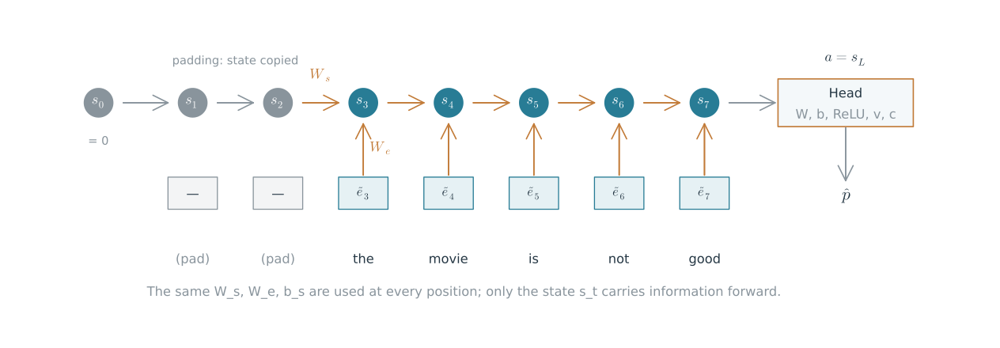

In [4]:
rnn_initial=recurrent_model(V_review;cell=:rnn)
@assert rnn_initial.E==classifier_initial.E
@printf("RNN parameters: %d (averaging model: %d)\n",parameter_count(rnn_initial),parameter_count(classifier_initial))
trace_rnn=recurrent_forward(rnn_initial,imdb.training.X[:,1:4])
println("For 4 reviews: a = s_L is ",size(trace_rnn.a),", probabilities ",round.(vec(trace_rnn.p);digits=3))
untrained=(model=rnn_initial,vocab=imdb.vocab)
for s in my_reviews[3:4]
    @printf("Untrained RNN, P(positive) = %.4f | %s\n",sentiment_probability(s,untrained),s)
end
@assert sentiment_probability(my_reviews[3],untrained)!=sentiment_probability(my_reviews[4],untrained)
rnn_diagram()

*Figure 1. The RNN unrolled over a short left-padded review. Each word vector enters the state through $W_e$; each state passes to the next through $W_s$. The state after the last word goes to the same head as before.*

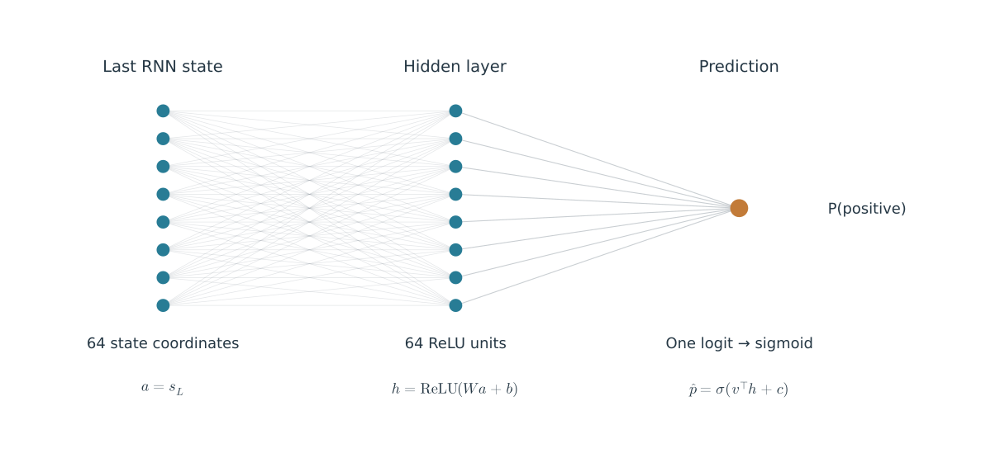

In [5]:
classifier_diagram(;input_title="Last RNN state",input_label="64 state coordinates",
    input_formula=L"a=s_L")

*Figure 2. The head of the RNN classifier is the head of the averaging model, with the same parameters $W,b,v,c$. Only its input changes: the average of the word vectors is replaced by the state after the last word, $a=s_L$. The LSTM below uses the same head in the same way.*

### 1.3 Backpropagation through time, and vanishing gradients

The loop in Figure 1 is a computation graph with $L=200$ copies of the same step.
**Backpropagation through time** is the chain rule applied along this unrolled chain.
Flux does it automatically.

**How far back does the gradient reach?** The word at position $t$ reaches the loss only through
$s_t,s_{t+1},\ldots,s_L$. By the chain rule (ignoring padding),

$$
\begin{aligned}
\frac{\partial s_L}{\partial s_t}&=\prod_{k=t+1}^{L}\frac{\partial s_k}{\partial s_{k-1}},\\[4pt]
\frac{\partial s_k}{\partial s_{k-1}}&=\operatorname{diag}\!\big(1-s_k\odot s_k\big)\,W_s .
\end{aligned}
$$

Each factor is the derivative of $\tanh$ (entries in $(0,1]$) times $W_s$, and position $t$ is $L-t$ factors away from the end.

- If a typical factor shrinks vectors, the product shrinks geometrically. For example, a factor of 0.9 per step leaves
  $$0.9^{100}\approx3\times10^{-5}$$
  after 100 steps. Words far from the end receive almost no gradient, so the model cannot learn from them.
  This is the **vanishing gradient** problem.
- If a typical factor enlarges vectors, the product grows geometrically. This is the **exploding gradient** problem.

**Measuring it.** The cell below takes 256 validation reviews that fill all 200 positions and computes,
for every position $t$,

$$r_t=\frac{\operatorname{mean}_n\big\lVert\partial L_n/\partial\tilde e_{t}\big\rVert}
           {\operatorname{mean}_n\big\lVert\partial L_n/\partial\tilde e_{L}\big\rVert}.$$

$r_t$ is the average gradient size at position $t$ relative to the last word; $r_L=1$.

**Gradient clipping.** All recurrent fits clip the gradient $g_P$ of every parameter array
$P\in\{E,W,b,v,c,W_e,W_s,b_s\}$ separately before each Adam update:

$$
g_P\;\leftarrow\;
\begin{cases}
g_P, & \lVert g_P\rVert\le\tau,\\[4pt]
\tau\,\dfrac{g_P}{\lVert g_P\rVert}, & \lVert g_P\rVert>\tau,
\end{cases}
\qquad \tau=1.
$$

Clipping keeps the direction and caps the length, so a single exploding gradient cannot cause a huge step.
It does not help with vanishing gradients: a small gradient passes through unchanged.

  position 199 (  1 words before the end): 9.27e-01
  position 190 ( 10 words before the end): 5.14e-01
  position 150 ( 50 words before the end): 2.75e-02
  position 100 (100 words before the end): 1.66e-03
  position   1 (199 words before the end): 6.84e-06


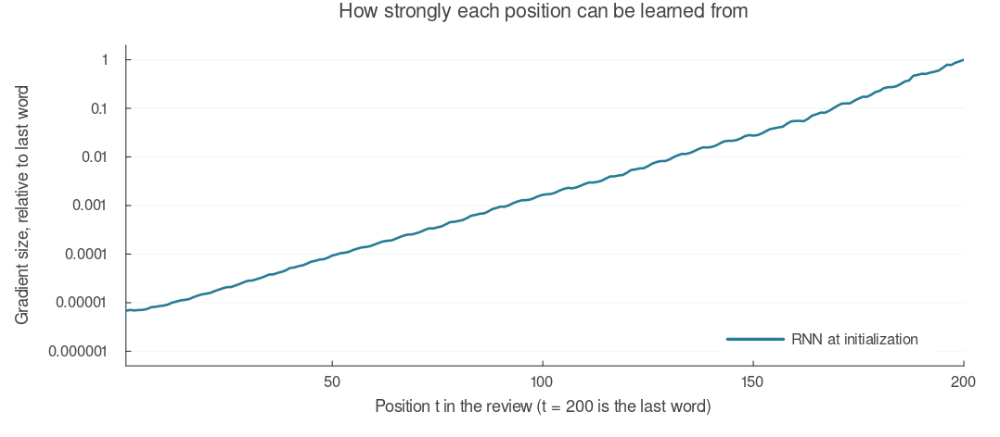

In [6]:
profile_rnn0=input_gradient_profile(rnn_initial,imdb.validation)
for t in (L_seq-1,L_seq-10,L_seq-50,L_seq-100,1)
    @printf("  position %3d (%3d words before the end): %.2e\n",t,L_seq-t,profile_rnn0[t])
end
gradient_profile_plot([("RNN at initialization",profile_rnn0,TEAL,:solid)])

*Figure 3. Gradient size at each position relative to the last word (log scale), for the untrained RNN. The signal decays roughly exponentially with distance from the end of the review.*

### 1.4 Train the RNN

**Loop.** The training loop of the averaging model, with the recurrent forward pass and the sequence input $X$.

**Loss and optimizer.** Binary cross-entropy, minimized with Adam on batches of 128 reviews (176 updates per epoch), learning rate 0.002.

**Epochs.** 8 epochs; the epoch with the lowest validation loss is kept. The validation loss is also recorded every 40 updates.

**Gradient clipping.** The gradient of each parameter array is rescaled to norm at most $\tau=1$ before each update.

**Diagnostics.** The fit also records the spectral radius of $W_s$, the gradient norm and the gradient profile, which are used below.

`TRAIN_RECURRENT=true` refits; otherwise the saved fits are loaded.

Epoch 1 | train 0.480 | validation 0.534 | val accuracy 76.9%
Epoch 2 | train 0.310 | validation 0.401 | val accuracy 82.3%
Epoch 3 | train 0.269 | validation 0.378 | val accuracy 83.9%
Epoch 4 | train 0.334 | validation 0.477 | val accuracy 81.8%
Epoch 5 | train 0.465 | validation 0.588 | val accuracy 68.9%
Epoch 6 | train 0.254 | validation 0.482 | val accuracy 80.0%
Epoch 7 | train 0.246 | validation 0.526 | val accuracy 77.8%
Epoch 8 | train 0.206 | validation 0.486 | val accuracy 80.6%
rnn_lr0.002: selected epoch 3 | test accuracy 82.54% | fit 214 seconds


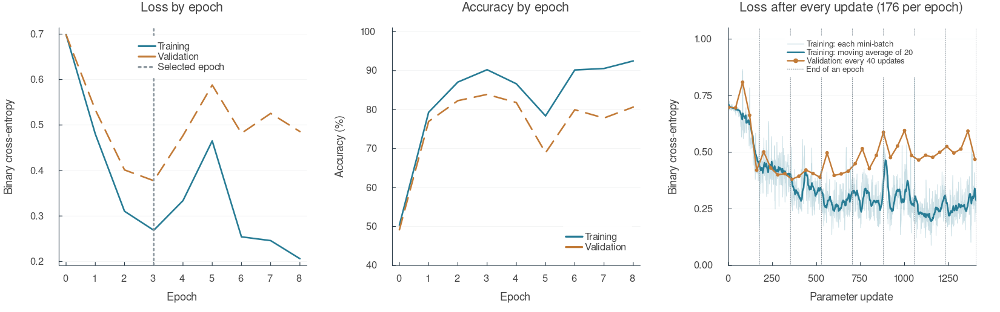

In [7]:
TRAIN_RECURRENT=false
rnn_base=fit_or_load("rnn_lr0.002",rnn_initial,imdb,RESULTS;lr=0.002f0,retrain=TRAIN_RECURRENT)
training_plot(rnn_base;loss_legend=:top)

*Figure 4. The RNN fit. Left and middle: after every epoch. Right: after every update, with validation every 40 updates.*

**What Figure 4 shows.**

- **Slow.** About 200 seconds, against about 10 for the averaging model: each update runs 200 steps one after another.
- **Less accurate.** The selected RNN (epoch 3) reaches 82.5% test accuracy, about five points below the averaging model.
- **Unstable.** In epochs 4 and 5 the training loss rises (0.269 → 0.334 → 0.465) and validation accuracy drops to 68.9%; early stopping keeps epoch 3.

A rising training loss means the updates make the fit worse. To find out why, we watch the inside of the network during training:
whether the updates push $W_s$ into a region where gradients vanish or explode.

### 1.5 Diagnose the instability

The loss shows that training is unstable, but not why. Deep-learning practice is to also **monitor quantities inside the network** during training.
The fit above recorded three of them, one per panel of Figure 5.

**Left: spectral radius of $W_s$.** After every update, compute the eigenvalues of $W_s$ and keep the largest absolute value:

$$\rho(W_s)=\max_i\,\lvert\lambda_i(W_s)\rvert.$$

Without the $\tanh$, the recurrence is the VAR $s_t=W_s s_{t-1}+W_e\tilde e_t+b_s$, and the effect of a word $k$ steps later scales like $\rho^{\,k}$:
it dies out if $\rho<1$ and explodes if $\rho>1$.

**Middle: gradient norm.** After every update, the length of the gradients of all parameters stacked into one vector:

$$\lVert g_q\rVert=\Big(\sum_{P}\lVert\nabla_P L_{\mathcal B_q}\rVert^2\Big)^{1/2}.$$

A value orders of magnitude above its typical level is a **spike**, the signature of an exploding gradient.

**Right: gradient profile.** At the end of every epoch, take 256 validation reviews with 200 words, differentiate the loss with respect to
every word vector, and average the length over reviews:

$$G_t=\frac1{256}\sum_{n=1}^{256}\Big\lVert\frac{\partial L}{\partial\tilde e_{t,n}}\Big\rVert,\qquad r_t=\frac{G_t}{G_{200}}.$$

$r_t$ measures how much word $t$ affects the loss, relative to the last word; if it is tiny, training cannot learn from word $t$.
The legend summarizes each curve by $\gamma$, the average factor per step back from the end:

$$r_1=\gamma^{199}\quad\Longrightarrow\quad\gamma=r_1^{\,1/199}.$$

$\gamma<1$ means a vanishing gradient, $\gamma>1$ an exploding one, and $\gamma\approx1$ that every position counts.
The factor is applied 199 times, so small deviations matter: $0.94^{199}\approx10^{-5}$.

**$\rho$ versus $\gamma$.** One step back multiplies the gradient by $\operatorname{diag}(1-s_k\odot s_k)\,W_s$:
$W_s$ scales it by about $\rho$, and the $\tanh$ derivative $1-s^2\le1$ shrinks it. Roughly,

$$\gamma\approx\rho\times\text{average }\tanh'.$$

$\rho$ is the gross growth factor and $\gamma$ the net one. The more states saturate near $\pm1$, where $\tanh'\approx0$, the larger the gap.

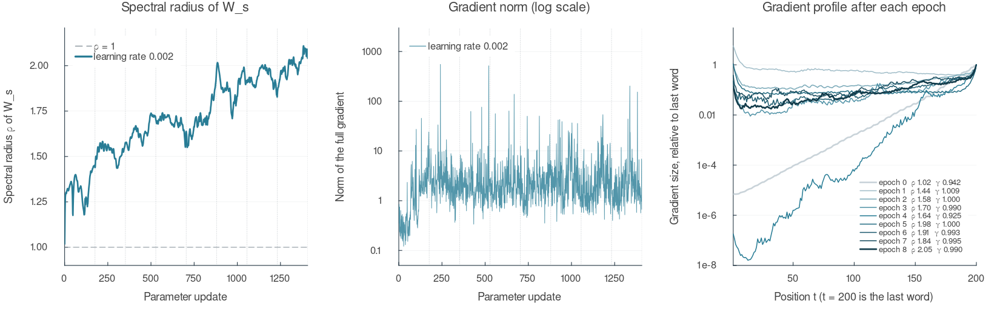

In [8]:
diagnosis_plot(rnn_base,"learning rate 0.002")

*Figure 5. Diagnostics of the RNN fit. Left: spectral radius of $W_s$ after every update; dotted lines mark the ends of epochs. Middle: norm of the full gradient (log scale). Right: gradient profile $r_t$ at the end of every epoch, from light (epoch 0) to dark (epoch 8), with $\rho$ and $\gamma$.*

**What Figure 5 shows.**

1. **Start: vanishing gradient.** $\rho\approx1$, but the $\tanh$ shrinkage makes $\gamma<1$: early words barely affect the loss.
2. **Training raises $\rho$ to fix it.** To use early words the RNN needs more persistence, so the gradient pushes the eigenvalues of $W_s$ up.
   After one epoch $\gamma\approx1$: the vanishing gradient is cured.
3. **But $\rho$ overshoots.** It keeps climbing, from about 1 to above 2. $\gamma$ stays near 1 only because more states saturate, and this balance is fragile:
   $\gamma$ swings between vanishing and exploding values from epoch to epoch, and batches whose states stay in the linear region of $\tanh$,
   where the net factor is close to $\rho$, produce gradient spikes. The losses jump when this happens (Figure 4).

**Why $\rho$ keeps rising: a self-reinforcing loop.**

$$\rho\uparrow\;\longrightarrow\;\text{more saturation}\;\longrightarrow\;\gamma\downarrow\;\longrightarrow\;\text{the gradient asks for more memory}\;\longrightarrow\;\rho\uparrow$$

1. **$\rho\uparrow\Rightarrow$ more saturation.** This link is mechanical: the network does not *want* saturation.
   A larger $W_s$ makes the input of the $\tanh$, $W_s s_{t-1}+W_e\tilde e_t+b_s$, larger, so more states are pushed close to $\pm1$.
2. **More saturation $\Rightarrow\gamma\downarrow$.** Saturated units have $\tanh'\approx0$, so the shrinkage per step grows and
   $\gamma\approx\rho\times\text{average }\tanh'$ falls: early words fade from the gradient again.
3. **$\gamma\downarrow\Rightarrow\rho\uparrow$.** Reviews whose verdict appears early are misclassified again, and the gradient of the loss
   points once more toward more persistence: larger eigenvalues of $W_s$.

Each rise in $\rho$ is largely absorbed by new saturation, which is why $\rho$ climbs above 2 while $\gamma$ stays near 1.

**A trap.** Once inside this loop, the RNN cannot get out: $\rho$ keeps drifting upward and validation loss never returns to its best value.
Three things keep it there:

- saturated units receive almost no gradient, so training cannot pull them back to the responsive middle of $\tanh$;
- leaving would require lowering $\rho$, but the loss only pushes $\rho$ up, for more memory;
- with a large learning rate, each step is too long for the fine adjustment that leaving would require.

The problem is the path, not the destination: with $\eta=0.002$, $\rho$ reaches 1.44 after one epoch and enters the saturated region before the loop can be avoided.

**Diagnosis.** Training moves in the right direction, toward more memory, but each step is too large:
$\rho$ goes far beyond what $\gamma\approx1$ requires.

### 1.6 Fix: a smaller learning rate

The direction of training is right (raise $\rho$ to remember earlier words), but each step is too large. Two facts explain why the step size controls $\rho$.

**1. Adam moves every coordinate by about $\eta$ per update**:

$$\lvert\Delta\theta_j\rvert=\eta\,\frac{\lvert\hat m_j\rvert}{\sqrt{\hat v_j}+\epsilon}\;\lesssim\;\eta .$$

Over the 176 updates of one epoch, an entry of $W_s$ can move by up to $176\,\eta$: 0.35 for $\eta=0.002$, three times its initial scale of 0.125.
$W_s$, and with it $\rho$, can change completely within one epoch.

**2. A step must be small relative to the curvature of the loss.** Gradient descent on $\tfrac12k(\theta-\theta^*)^2$ gives

$$\theta_q-\theta^*=(1-\eta k)\,(\theta_{q-1}-\theta^*),$$

which converges only if $\eta<2/k$; otherwise every step overshoots. Near $\rho\approx1$ the loss is very steep in $W_s$ (large $k$),
because a small change in $W_s$ changes the persistence of 200 steps.

A smaller $\eta$ lets $\rho$ rise gradually and stop once $\gamma\approx1$, before the self-reinforcing loop starts.
The cell below refits the RNN with $\eta=0.0005$; everything else is unchanged.

Epoch 1 | train 0.670 | validation 0.678 | val accuracy 58.0%
Epoch 2 | train 0.370 | validation 0.417 | val accuracy 82.7%
Epoch 3 | train 0.271 | validation 0.368 | val accuracy 84.7%
Epoch 4 | train 0.182 | validation 0.331 | val accuracy 87.4%
Epoch 5 | train 0.116 | validation 0.345 | val accuracy 87.6%
Epoch 6 | train 0.087 | validation 0.425 | val accuracy 86.3%
Epoch 7 | train 0.059 | validation 0.432 | val accuracy 87.1%
Epoch 8 | train 0.040 | validation 0.467 | val accuracy 86.6%


rnn_lr0.0005: selected epoch 4 | test accuracy 84.75% | fit 199 seconds


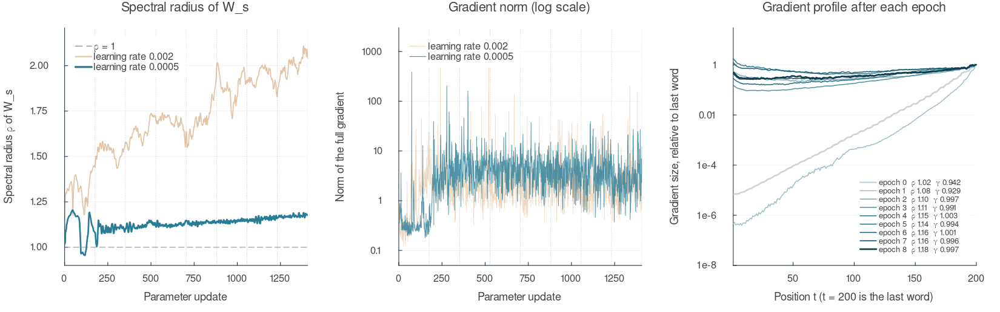

In [9]:
rnn_run=fit_or_load("rnn_lr0.0005",rnn_initial,imdb,RESULTS;lr=0.0005f0,retrain=TRAIN_RECURRENT)
diagnosis_plot(rnn_run,"learning rate 0.0005";compare=rnn_base,compare_label="learning rate 0.002")

*Figure 6. The same diagnostics for the refit with learning rate 0.0005 (teal), with the original fit (amber, faded) for comparison in the first two panels.*

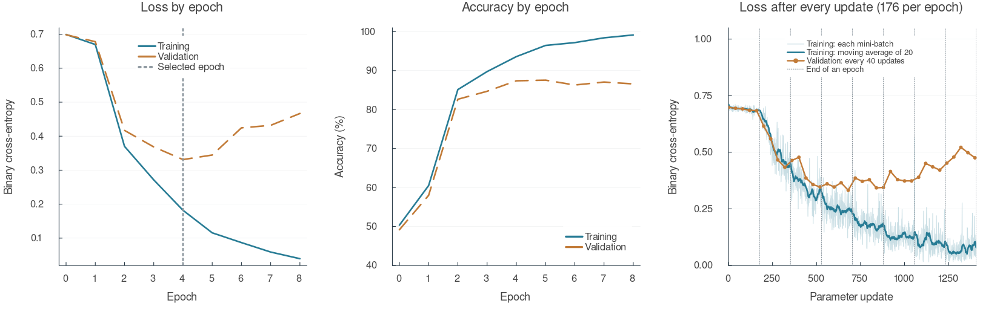

In [10]:
training_plot(rnn_run;loss_legend=:top)

*Figure 7. The refit RNN, drawn like Figure 4.*

**What changes with $\eta=0.0005$ (Figures 6 and 7).**

1. **$\rho$ rises slowly and stops near 1.15**, instead of climbing above 2. From epoch 2 on, $\gamma\approx1$: every position of the review can be learned from.
2. **$\gamma\approx1$ is reached without saturation**, so the self-reinforcing loop never starts. Test accuracy rises from 82.5% to 84.8%.
3. **The instability is reduced, not eliminated.** Spikes are rarer and smaller, and Adam's bounded steps keep a few bad updates from pushing the parameters far.
   The late rise in validation loss is ordinary overfitting; early stopping selects epoch 4.

**The target is $\gamma\approx1$, not a particular $\rho$.** Since $\tanh'\le1$ shrinks every step, $\gamma\approx1$ requires $\rho$ slightly above 1;
how far above depends on how saturated the states are.

From here on, "the RNN" means this refit.

### 1.7 Look inside the network: saturated states

So far we measured the network through its gradients. Here we look at the states themselves, for the two selected models
($\eta=0.002$, epoch 3, and $\eta=0.0005$, epoch 4), on the same 256 validation reviews. Figure 8 has one row per model.

A unit is **saturated** when its value is close to $\pm1$, where $\tanh'=1-s^2\approx0$ and almost no gradient passes.

**Left: the states of one review.** Each column is the state vector $s_t$ after word $t$ (words 151–200), each row is one of the 64 units,
and the color is its value: dark orange near $+1$, dark blue near $-1$, white near 0. Rows are sorted by average $\tanh'$, most saturated on top.
A pale row is a unit that responds to the words; a dark row is a saturated unit.

**Middle: all state values.** A histogram of all $64\times200\times256$ values. A U shape (values piled up near $\pm1$) means saturation;
a bell shape around 0 means the units work in the responsive middle of $\tanh$.

**Right: gradient passed per unit.** For each unit, the average of $\tanh'=1-s^2$ over all positions and reviews, sorted.
This is the shrinkage that turns $\rho$ into $\gamma$:

$$\gamma\approx\rho\times\text{average }\tanh'.$$

learning rate 0.002   eigenvalue of W_s with the largest absolute value: -1.70+0.00i
learning rate 0.0005  eigenvalue of W_s with the largest absolute value: 0.37-1.09i


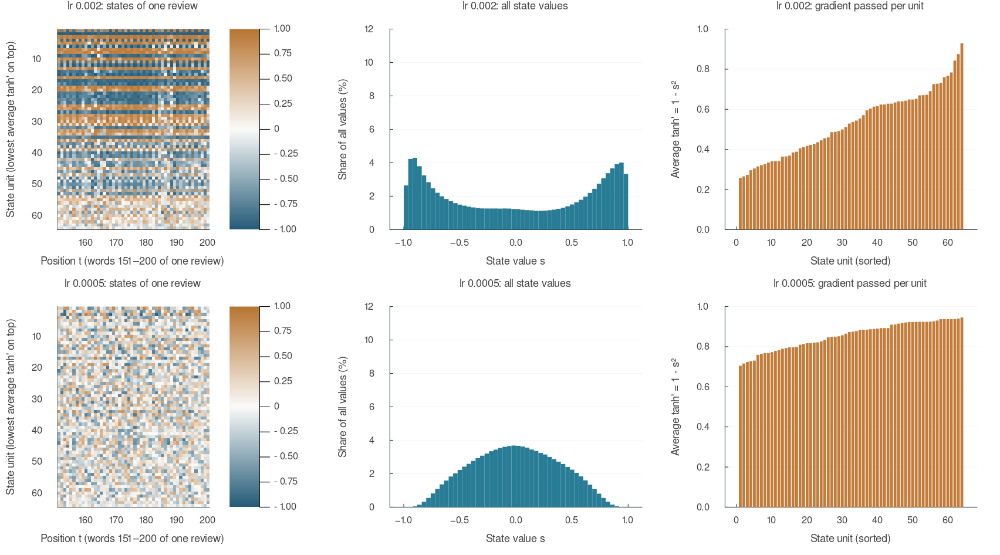

In [11]:
act_base=state_trajectories(rnn_base.model,imdb.validation)
act_run=state_trajectories(rnn_run.model,imdb.validation)
for (name,m) in (("learning rate 0.002",rnn_base.model),("learning rate 0.0005",rnn_run.model))
    ev=eigvals(m.Ws); z=ev[argmax(abs.(ev))]
    @printf("%-21s eigenvalue of W_s with the largest absolute value: %.2f%+.2fi\n",name,real(z),imag(z))
end
activation_plot([("lr 0.002",act_base.S),("lr 0.0005",act_run.S)])

*Figure 8. Inside the recurrent state of the two selected RNNs, for 256 validation reviews. Top row: learning rate 0.002 (epoch 3). Bottom row: learning rate 0.0005 (epoch 4). Left: the 64 state units (rows) after each of words 151–200 (columns) of one review. Middle: distribution of all state values. Right: average $\tanh'$ of each unit, sorted.*

**What Figure 8 shows.**

1. **Learning rate 0.002: many saturated units.** The heatmap has dark rows on top, the histogram is U-shaped, and the average $\tanh'$ is about 0.5.
   Some saturated units hold one value whatever the words are; others **flip sign at every word**.
2. **Learning rate 0.0005: no saturation.** The heatmap is pale, the histogram is bell-shaped, and the average $\tanh'$ is about 0.9.
3. **Both reach $\gamma\approx1$, in different ways:** a large $\rho$ offset by heavy saturation ($1.70\times0.53$), or a small $\rho$ with little saturation ($1.15\times0.86$).
   The first is the self-reinforcing loop made visible.

**Where the flipping comes from.** The leading eigenvalue of $W_s$ in the first model is $-1.70$: real and negative.
Along its eigenvector the recurrence behaves like $x_t=-1.7\,x_{t-1}$: the sign flips every word, the size grows, and the $\tanh$ caps it near $\pm0.9$.

**Why saturation is harmful.** A saturated unit barely depends on the words, so it carries little information about the review,
and since $\tanh'\approx0$ blocks its gradient, it can hardly be trained back. No unit is dead, though: even the most saturated one passes about a quarter of the gradient (right panel).

## 2. Long short-term memory (LSTM)

**The problem.** The RNN keeps everything in one state and rewrites all of it at every word,
$s_t=\tanh(W_s s_{t-1}+W_e\tilde e_t+b_s)$. The gradient from the last word back to word $t$ therefore passes through one matrix and one $\tanh'$ per step:

$$
\frac{\partial s_L}{\partial s_t}=\prod_{k=t+1}^{L}\operatorname{diag}(\tanh'_k)\,W_s .
$$

This product rarely stays near 1: it shrinks towards 0 (vanishing) or blows up (exploding). The RNN diagnostics measured exactly this through $\rho$ and saturation.

**The idea.** The **LSTM** (Hochreiter and Schmidhuber, 1997) splits the two jobs of the RNN state, *storing* and *computing*, between two vectors:

$$
\begin{aligned}
C_t&=f_t\odot C_{t-1}+i_t\odot g_t &&\text{store: only coordinatewise products and sums}\\
s_t&=o_t\odot\tanh(C_t) &&\text{show: a squashed, selected view of }C_t
\end{aligned}
$$

- The **cell state** $C_t$ is the memory, like a capital stock $K_t=(1-\delta)K_{t-1}+I_t$: the old value is kept in proportion $f_t$ and new content $i_t\odot g_t$ is added. No matrix and no $\tanh$ sit on this path, so information and gradients can travel far when $f_t\approx1$.
- The **state** $s_t$ is what the rest of the network reads: the gates of the next step (through weight matrices) and, after the last word, the head. All nonlinear computation happens on this path.
- The **gates** $f_t,i_t,o_t\in(0,1)^{64}$ decide what to erase, what to write and what to show; $g_t$ is the new content.

With a single vector, memory would again pass through $\tanh(W\cdot)$ at every word, which is the RNN.

**The name.** In the original terminology the trained weights are the *long-term* memory and the state within one review is the *short-term* memory.
In the RNN this short-term memory fades within a few dozen words; the LSTM is a short-term memory that lasts **long**.

### 2.1 The LSTM

Figure 9 unrolls the LSTM over the review of Figure 1. The only difference from the RNN is that each step
passes **two** vectors to the next word, the cell state $C_t$ and the state $s_t$:

$$
\begin{aligned}
(C_t,\,s_t)&=\text{LSTM}\big(C_{t-1},\,s_{t-1},\,\tilde e_t\big), \qquad C_0=s_0=0,\\
a&=s_L .
\end{aligned}
$$

$C_{t-1}$ is not data: it is what the previous step left behind.
Only $s_t$ goes to the head.

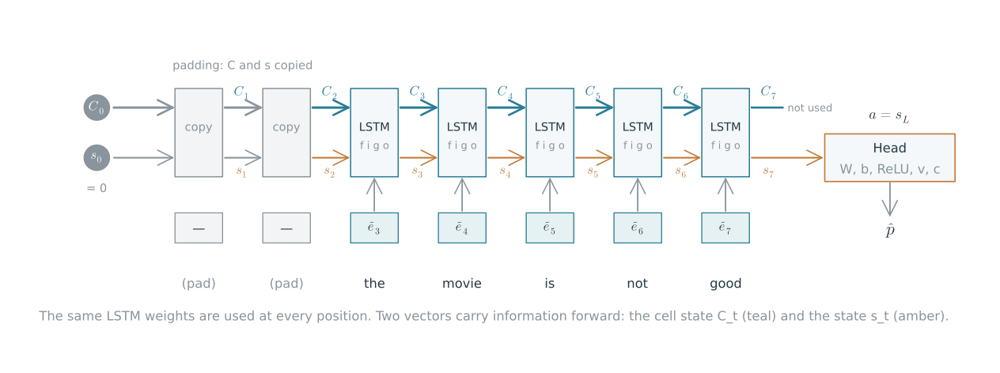

In [12]:
lstm_diagram()

*Figure 9. The LSTM unrolled over a short left-padded review. Each step reads $C_{t-1}$, $s_{t-1}$ and the word vector $\tilde e_t$, and passes $C_t$ and $s_t$ to the next word. The state after the last word goes to the head.*

**Inside one step.** Four **gates** are computed from the previous state and the current word,
each exactly like the RNN's update but with its own weights:

$$
\begin{aligned}
f_t&=\sigma\big(W_s^{f}s_{t-1}+W_e^{f}\tilde e_t+b^{f}\big) &&\text{forget gate}\\
i_t&=\sigma\big(W_s^{i}s_{t-1}+W_e^{i}\tilde e_t+b^{i}\big) &&\text{input gate}\\
g_t&=\tanh\big(W_s^{g}s_{t-1}+W_e^{g}\tilde e_t+b^{g}\big) &&\text{candidate}\\
o_t&=\sigma\big(W_s^{o}s_{t-1}+W_e^{o}\tilde e_t+b^{o}\big) &&\text{output gate}
\end{aligned}
$$

They update the cell state and the state, coordinate by coordinate:

$$
\begin{aligned}
C_t&=f_t\odot C_{t-1}+i_t\odot g_t,\\
s_t&=o_t\odot\tanh(C_t).
\end{aligned}
$$

For one coordinate $r$:

- **Forget gate** $f_{t,r}\in(0,1)$: the share of the old memory $C_{t-1,r}$ that is kept, like $1-\delta$ in $K_t=(1-\delta)K_{t-1}+I_t$.
- **Candidate** $g_{t,r}\in(-1,1)$: the new content the current word proposes, like the RNN's update.
- **Input gate** $i_{t,r}\in(0,1)$: how much of the candidate is written, so $i_{t,r}g_{t,r}$ plays the role of investment $I_t$.
- **Output gate** $o_{t,r}\in(0,1)$: how much of the memory is shown in $s_t$.

Figure 10 draws this step as a network of units, in the style of Figure 2.
The grey fans are the four matrix multiplications above; the coloured lines are the coordinatewise products and sums.
The top line $C_{t-1}\to C_t$ is the only connection between steps with no matrix and no $\tanh$.

Here $f_t$ is a gate, unrelated to the word-frequency vector $f$ of the averaging model. Padding positions copy both $s_{t-1}$ and $C_{t-1}$, as in the RNN.

**Parameters.** Each gate has its own $W_s$ ($64\times64$), $W_e$ ($64\times64$) and bias ($64$); in code they are stacked
into one $256\times64$ matrix of each kind, four times the RNN's recurrent parameters.
They are initialized like the RNN's, except $b^f=1$, so $f_t\approx\sigma(1)\approx0.73$: the untrained LSTM keeps most of its memory by default.

LSTM parameters: 1317249 | stacked W_e (256, 64), W_s (256, 64), bias (256,)


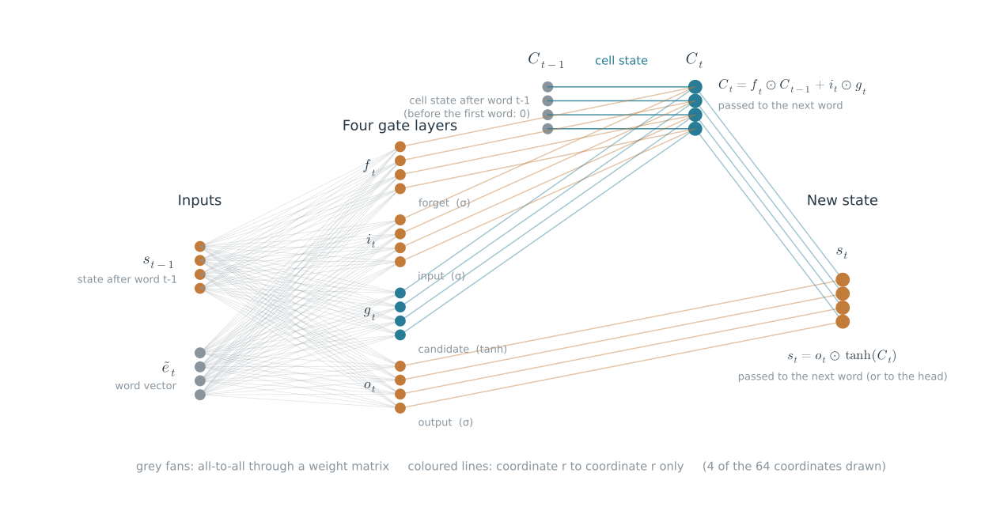

In [13]:
lstm_initial=recurrent_model(V_review;cell=:lstm)
@assert lstm_initial.E==classifier_initial.E
@printf("LSTM parameters: %d | stacked W_e %s, W_s %s, bias %s\n",parameter_count(lstm_initial),
    string(size(lstm_initial.We)),string(size(lstm_initial.Ws)),string(size(lstm_initial.bs)))
lstm_network_diagram()

*Figure 10. One LSTM step as a network of units, four of the 64 coordinates per vector. Grey: all-to-all connections through a weight matrix. Coloured: coordinate-by-coordinate connections. The cell state runs along the top.*

### 2.2 Why the cell state lets gradients travel further

Follow the gradient along the top line of Figure 10 (the cell state). Holding the gates fixed,

$$
\frac{\partial C_k}{\partial C_{k-1}}=\operatorname{diag}(f_k)
\qquad\Longrightarrow\qquad
\frac{\partial C_L}{\partial C_t}=\prod_{k=t+1}^{L}\operatorname{diag}(f_k).
$$

Compare this with the RNN:

| | One factor of the product | Controlled by |
|---|---|---|
| RNN state | $\operatorname{diag}(1-s_k\odot s_k)\,W_s$ | a fixed matrix and the $\tanh$ derivative |
| LSTM cell state | $\operatorname{diag}(f_k)$ | the forget gates, which the model sets at every step |

Where a coordinate's forget gate stays close to 1, its memory and its gradient pass through many steps almost unchanged.
This gives the network its name: a short-term memory (the state) that can last a long time.

The cell below repeats the measurement $r_t$ of Figure 3 for the untrained LSTM.

   10 words before the end: RNN 5.14e-01 | LSTM 3.33e-01
   50 words before the end: RNN 2.75e-02 | LSTM 9.75e-02
  100 words before the end: RNN 1.66e-03 | LSTM 2.30e-02
  199 words before the end: RNN 6.84e-06 | LSTM 8.04e-04


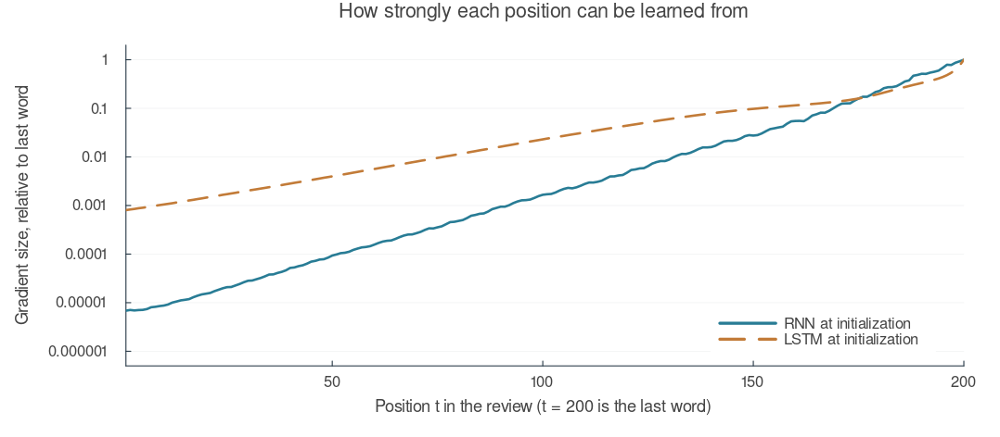

In [14]:
profile_lstm0=input_gradient_profile(lstm_initial,imdb.validation)
for t in (L_seq-10,L_seq-50,L_seq-100,1)
    @printf("  %3d words before the end: RNN %.2e | LSTM %.2e\n",L_seq-t,profile_rnn0[t],profile_lstm0[t])
end
gradient_profile_plot([("RNN at initialization",profile_rnn0,TEAL,:solid),
                       ("LSTM at initialization",profile_lstm0,AMBER,:dash)])

*Figure 11. Gradient size by position relative to the last word, for the untrained RNN and LSTM. The LSTM's signal also decays, but much more slowly.*

### 2.3 Train the LSTM

The same training settings as the RNN, learning rate 0.002.

Epoch 1 | train 0.306 | validation 0.365 | val accuracy 85.3%
Epoch 2 | train 0.202 | validation 0.334 | val accuracy 85.7%
Epoch 3 | train 0.118 | validation 0.360 | val accuracy 87.6%
Epoch 4 | train 0.070 | validation 0.391 | val accuracy 87.6%
Epoch 5 | train 0.059 | validation 0.422 | val accuracy 87.1%
Epoch 6 | train 0.042 | validation 0.478 | val accuracy 86.6%
Epoch 7 | train 0.048 | validation 0.496 | val accuracy 86.1%
Epoch 8 | train 0.016 | validation 0.584 | val accuracy 86.4%
lstm: selected epoch 2 | test accuracy 84.65% | fit 789 seconds


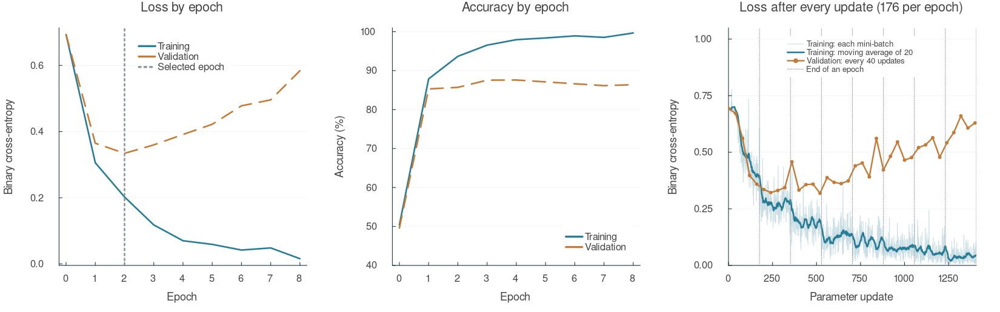

In [15]:
lstm_run=fit_or_load("lstm",lstm_initial,imdb,RESULTS;retrain=TRAIN_RECURRENT)
training_plot(lstm_run;loss_legend=:top)

*Figure 12. The LSTM fit, drawn like Figure 4.*

Compare Figure 12 with the refit RNN in Figure 7:

- **Faster start, without tuning.** Validation accuracy after one epoch is 85.3%, against 58.0% for the RNN.
  The LSTM is stable at learning rate 0.002, the setting that destabilized the RNN. Figure 13 shows why.
- **Similar final accuracy.** The best validation loss, 0.334, comes at epoch 2 (RNN: 0.331 at epoch 4),
  and the selected LSTM reaches 84.65% test accuracy (RNN: 84.75%).
- **The same overfitting as the averaging model.** Training loss falls to 0.02 while validation loss rises from 0.334 to 0.584.
  With 1.3 million parameters and 22,411 training reviews, the LSTM can also memorize the training set.
- **The highest cost.** Each step computes four gate blocks instead of one, so the fit takes several times longer than an RNN fit.

**Diagnostics.** Figure 13 repeats the three panels of Figure 6 for the LSTM; faded amber is the refit RNN.

- Left: the LSTM has four recurrent blocks $W_s^f,W_s^i,W_s^o,W_s^g$, one per gate; the panel shows $\rho$ of each. $W_s^g$ plays the role of the RNN's $W_s$.
- Right: the legend adds the average forget gate $f$.

Along the cell state, the gradient is multiplied by the forget gate at every word:

$$
\frac{\partial C_L}{\partial C_t}=\prod_{k=t+1}^{L}\operatorname{diag}(f_k),
$$

so only units with $f\approx1$ carry memory across many words. The cell prints the average forget gate of each unit.

untrained LSTM: average forget gate 0.73, largest unit 0.74; that unit keeps about 4e-27 of its memory over 199 words


trained   LSTM: average forget gate 0.72, largest unit 0.81; that unit keeps about 7e-19 of its memory over 199 words


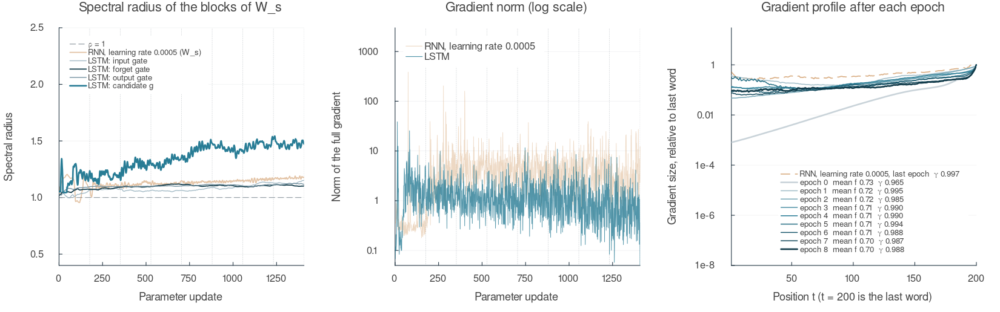

In [16]:
for (name,m) in [("untrained",lstm_initial),("trained",lstm_run.model)]
    f=forget_gate_by_unit(m,imdb.validation)
    @printf("%-9s LSTM: average forget gate %.2f, largest unit %.2f; that unit keeps about %.0e of its memory over 199 words\n",
        name,mean(f),maximum(f),maximum(f)^199)
end
lstm_diagnosis_plot(lstm_run;compare=rnn_run,compare_label="RNN, learning rate 0.0005")

*Figure 13. LSTM training diagnostics, in the layout of Figure 6. Faded amber: the refit RNN.*

- **Smaller gradients.** Fewer and lower spikes than the RNN, at four times its learning rate (0.002 against 0.0005).
- **Flat profile.** After one epoch $\gamma\approx1$: early words keep their influence.
- **Not through the forget gates.** They stay near their start $\sigma(1)\approx0.73$; the largest unit reaches 0.81, and $0.81^{199}\approx10^{-19}$.
  The cell state does not carry long memory in this fit.
- **Through $s_t$ instead, as in the RNN.** $\rho(W_s^g)$ rises to about 1.4. The gates, in $(0,1)$, damp every step on this path, which likely prevents explosion.

A likely reason: reviewers state their verdict near the end, so the labels give little reason to remember 200 words back.

### 2.4 Read a sentence word by word

A recurrent model has a prediction after **every** word: apply the head to $s_t$ instead of $s_L$.
Figure 14 plots this running prediction for a sentence whose verdict changes halfway through.
The averaging model has no such running state.

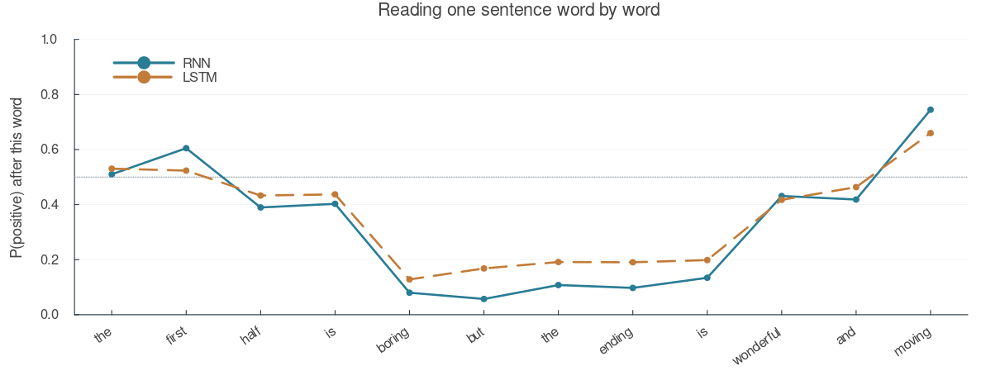

In [17]:
reading_text="The first half is boring, but the ending is wonderful and moving."
reading_plot([("RNN",reading_probabilities(reading_text,rnn_run),TEAL,:solid),
              ("LSTM",reading_probabilities(reading_text,lstm_run),AMBER,:dash)])

*Figure 14. P(positive) after each word, computed by applying the trained head to the state $s_t$. The last point of each curve is the model's prediction for the whole sentence.*

Both curves start near 0.5 and follow the sentence:

- they drop at "boring" (to 0.08 for the RNN and 0.13 for the LSTM) and stay low through "but the ending is";
- they rise at "wonderful" and "moving" and end at 0.74 and 0.66.

The final prediction follows the **latest** sentiment words, because the later words have partly overwritten
the state that "boring" created. Averaging cannot produce this pattern: it gives every position the same weight.

The word "but" barely moves either curve. The models have not learned that "but" signals a reversal;
the recovery comes from the positive words after it.

## 3. Reading all words at once: a Transformer

In the RNN and the LSTM, word $t$ reaches $a$ only through $L-t$ sequential steps.
The **Transformer** (Vaswani et al., 2017) lets every word look at every other word directly, in every layer, through a learned weighted average.
**BERT** (Devlin et al., 2019) is a stack of such layers. We build a small BERT-style model and train it from scratch.

### 3.1 Architecture

$$
\begin{aligned}
x^{(0)}_t&=\tilde e_t+p_t &&\text{word vector plus position vector}\\
h_t&=\mathrm{LN}\big(x^{(\ell-1)}_t+\mathrm{Attn}_t(x^{(\ell-1)}_1,\ldots,x^{(\ell-1)}_L)\big) &&\text{attention, Add \& Norm}\\
x^{(\ell)}_t&=\mathrm{LN}\big(h_t+\mathrm{FFN}(h_t)\big),\qquad \ell=1,\ldots,K &&\text{feedforward, Add \& Norm}\\
a&=\tfrac1T\textstyle\sum_t x^{(K)}_t,\qquad \hat p=\sigma\big(v^\top\mathrm{ReLU}(Wa+b)+c\big) &&\text{pooling and head}
\end{aligned}
$$

Sizes: $d=64$, $K=2$ layers, $H=4$ heads of $d_h=16$, feedforward width 128, $L=200$. With $K=0$ and $p_t=0$ this is the averaging model.

Word vectors E                         1280000
Position vectors P                       12800
Attention W_Q, W_K, W_V, W_O, b_O        32896
Layer norms γ, β                           512
Feedforward W_1, b_1, W_2, b_2           33152
Head W, b, v, c                           4225
Total                                  1363585   (averaging model: 1284225)


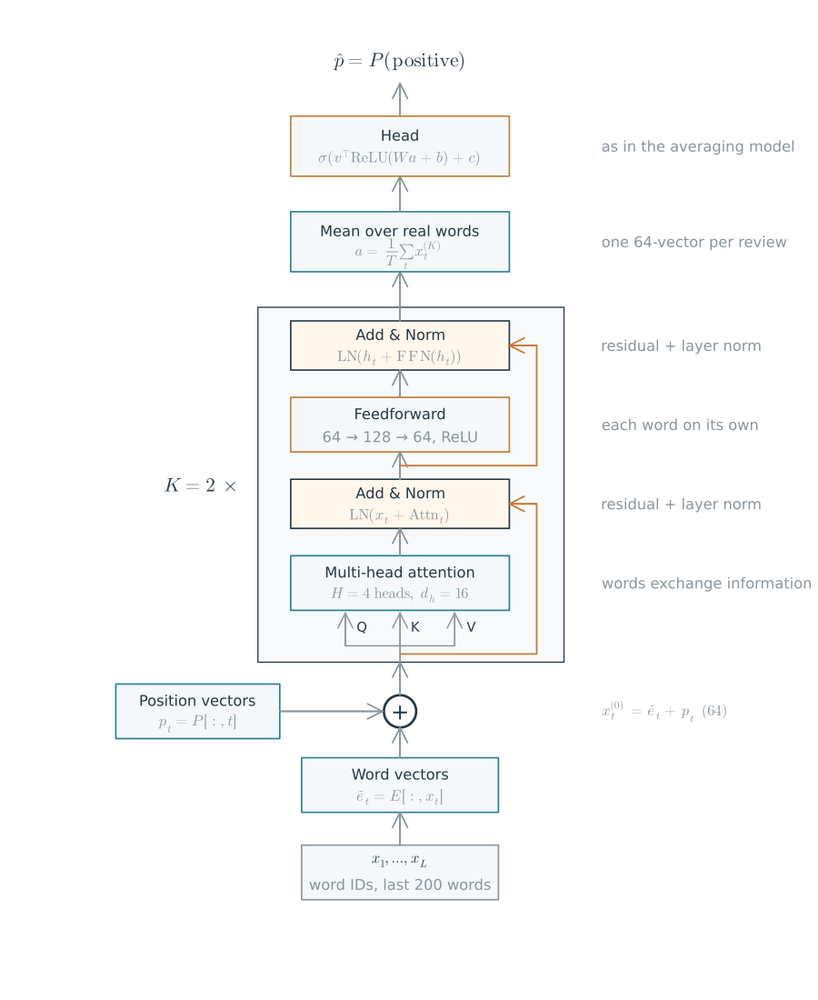

In [18]:
transformer_initial=transformer_model(V_review)
@assert transformer_initial.E==classifier_initial.E
tm=transformer_initial
blocks=[("Word vectors E",(tm.E,)),("Position vectors P",(tm.P,)),
        ("Attention W_Q, W_K, W_V, W_O, b_O",(tm.Wq,tm.Wk,tm.Wv,tm.Wo,tm.bo)),
        ("Layer norms γ, β",(tm.g1,tm.β1,tm.g2,tm.β2)),
        ("Feedforward W_1, b_1, W_2, b_2",(tm.W1,tm.b1,tm.W2,tm.b2)),
        ("Head W, b, v, c",(tm.W,tm.b,tm.v,tm.c))]
for (name,arrays) in blocks
    @printf("%-36s %9d\n",name,sum(length,arrays))
end
@printf("%-36s %9d   (averaging model: %d)\n","Total",parameter_count(tm),parameter_count(classifier_initial))
transformer_architecture_diagram()

*Figure 15. The Transformer classifier. The box is one encoder layer, repeated $K=2$ times; amber arrows are residual connections.*

### 3.2 Position vectors

$$
p_t=P[:,t],\qquad P\in\mathbb R^{64\times200}.
$$

- Attention is a weighted average, and an average ignores order. $p_t$ makes the same word differ by position.
- The original Transformer uses fixed vectors, $p_{t,2i}=\sin(t/10000^{2i/d})$, $p_{t,2i+1}=\cos(t/10000^{2i/d})$.
  BERT, and our model, learn $P$ like $E$; inputs never exceed 200 positions.
- With left padding the last word is always at $t=200$, so $p_t$ encodes the distance to the end.

### 3.3 Attention with one head

Each word vector gives a query, a key and a value ($W_Q,W_K,W_V\in\mathbb R^{16\times64}$):

$$
q_t=W_Qx_t,\qquad k_s=W_Kx_s,\qquad v_s=W_Vx_s .
$$

Position $t$ scores every key, normalizes, and averages the values:

$$
e_{ts}=\frac{q_t^\top k_s}{\sqrt{d_h}},\qquad
\alpha_{ts}=\frac{\exp(e_{ts})}{\sum_{s'}\exp(e_{ts'})},\qquad
o_t=\sum_s\alpha_{ts}\,v_s .
$$

- Query: what word $t$ looks for. Key: what word $s$ offers. Value: what word $s$ passes on.
- $\sqrt{d_h}$: $q_t^\top k_s$ sums 16 products, so its variance is about 16; dividing keeps the softmax from saturating.
- Padding keys get $e_{ts}=-\infty$, so $\alpha_{ts}=0$. Equal scores give $\alpha_{ts}=1/T$: plain averaging.

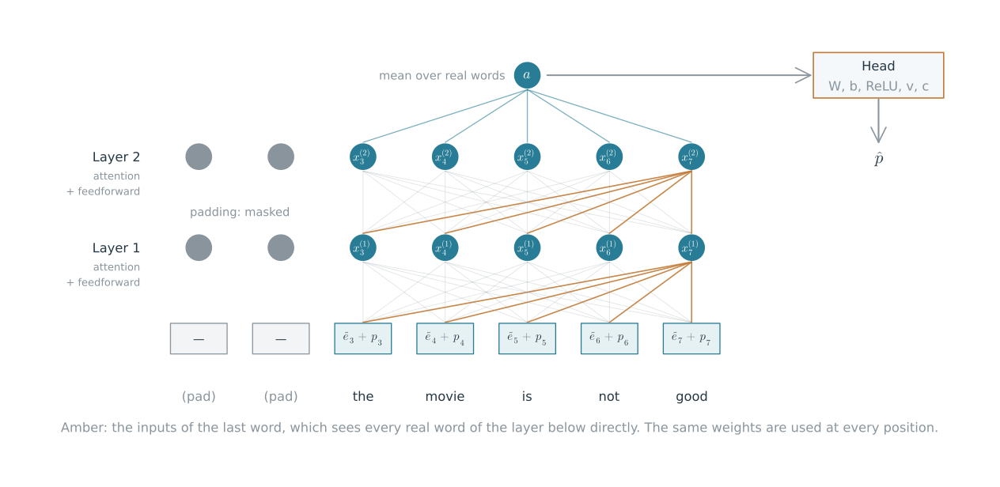

In [19]:
transformer_diagram()

*Figure 16. Every vector of a layer is computed from all real words of the layer below (amber: the inputs of the last word). Padding is masked.*

**Matrix form.** Stack the word vectors of a review as rows, $X\in\mathbb R^{T\times64}$:

$$
Q=XW_Q^\top,\quad K=XW_K^\top,\quad V=XW_V^\top\in\mathbb R^{T\times d_h},\qquad
S=QK^\top/\sqrt{d_h}\in\mathbb R^{T\times T},\qquad A=\mathrm{softmax}_{\text{rows}}(S+M),\qquad O=AV .
$$

- $S$: scores $e_{ts}$, every query against every key. $M$: the mask, $M_{ts}=-\infty$ for padding keys and $0$ otherwise.
- Row $t$ of $A$ holds the weights $\alpha_{ts}$; row $t$ of $O$ is $o_t$.
- Memory grows with $T^2$.

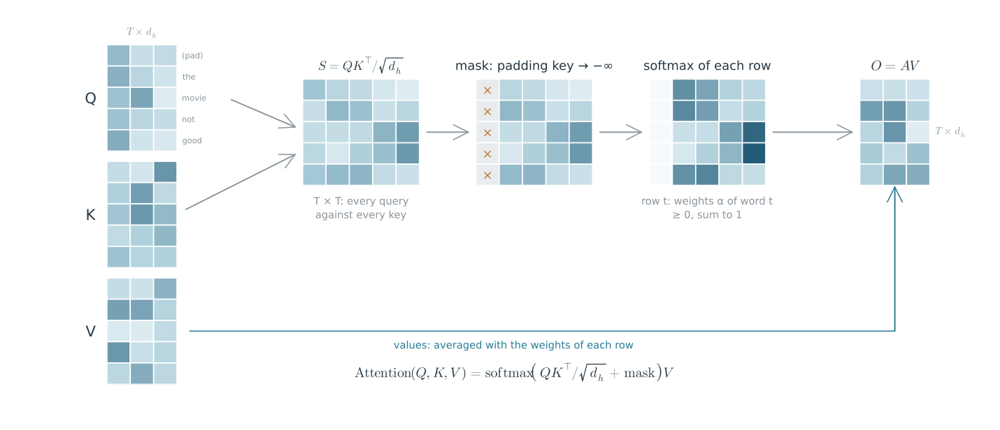

In [20]:
attention_matrix_diagram()

*Figure 17. Scaled dot-product attention in matrix form, five positions, the first one padding. Shades are illustrative.*

### 3.4 Multi-head attention

$$
\begin{aligned}
o^{(h)}_t&=\textstyle\sum_s\alpha^{(h)}_{ts}\,v^{(h)}_s,\qquad h=1,\ldots,4 &&\text{each head: own }W^{(h)}_Q,W^{(h)}_K,W^{(h)}_V\in\mathbb R^{16\times64}\\
\mathrm{Attn}_t&=W_O\,\big[o^{(1)}_t;\ldots;o^{(4)}_t\big]+b_O &&W_O\in\mathbb R^{64\times64}\text{ mixes the heads}
\end{aligned}
$$

- One head gives one set of weights per word; four heads can attend to four different things.
- Same cost as one 64-dimensional head: stacked, the $W^{(h)}_Q$ form one $64\times64$ matrix.
- Parameters per layer: $4\cdot64\cdot64+64=16{,}448$.

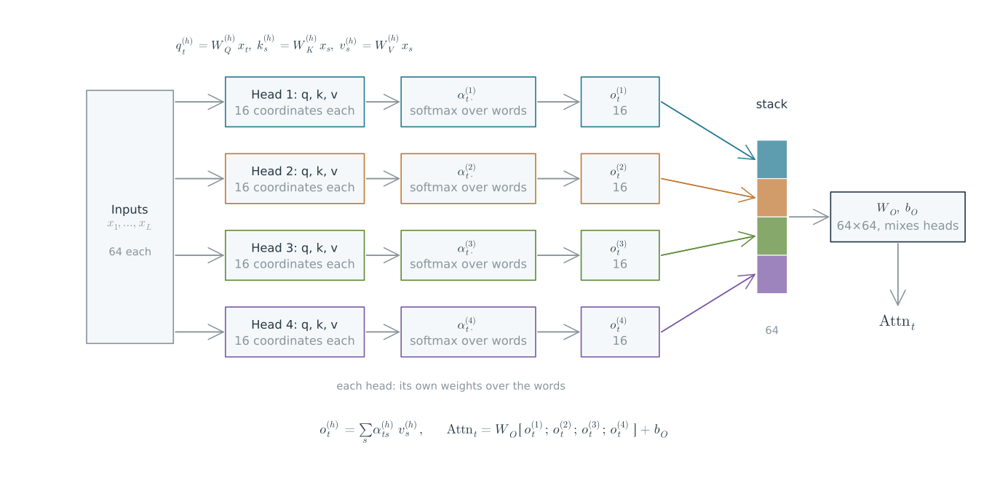

In [21]:
multihead_diagram()

*Figure 18. Multi-head attention for one position: four heads of 16 coordinates, stacked to 64 and mixed by $W_O$.*

### 3.5 Add & Norm

$$
h_t=\mathrm{LN}(x_t+\mathrm{Attn}_t),\qquad
\mathrm{LN}(y)=\gamma\odot\frac{y-\mu}{\sqrt{\sigma^2+\varepsilon}}+\beta,\qquad
\mu=\tfrac1{64}\textstyle\sum_iy_i,\quad\sigma^2=\tfrac1{64}\sum_i(y_i-\mu)^2 .
$$

- **Residual** $x_t+\cdots$: the layer learns a change. Since $\partial(x+f(x))/\partial x=I+\partial f/\partial x$, the gradient always has a direct path back, as along the LSTM cell state.
- **Layer norm**: per word, across its 64 coordinates (not across words or reviews). It keeps the size of the vectors stable, which the next softmax needs.

### 3.6 Feedforward network

$$
\begin{aligned}
u_t&=W_1h_t+b_1 &&W_1\in\mathbb R^{128\times64}:\ \text{widen}\\
f_t&=W_2\,\mathrm{ReLU}(u_t)+b_2 &&W_2\in\mathbb R^{64\times128}:\ \text{narrow}\\
x'_t&=\mathrm{LN}(h_t+f_t) &&\text{Add \& Norm}
\end{aligned}
$$

- The same weights for every word; words do not interact here.
- Attention is linear in the values; this is where each word's vector is transformed nonlinearly.
- 128 candidate features; ReLU switches some off for each word. Parameters per layer: 16,576.

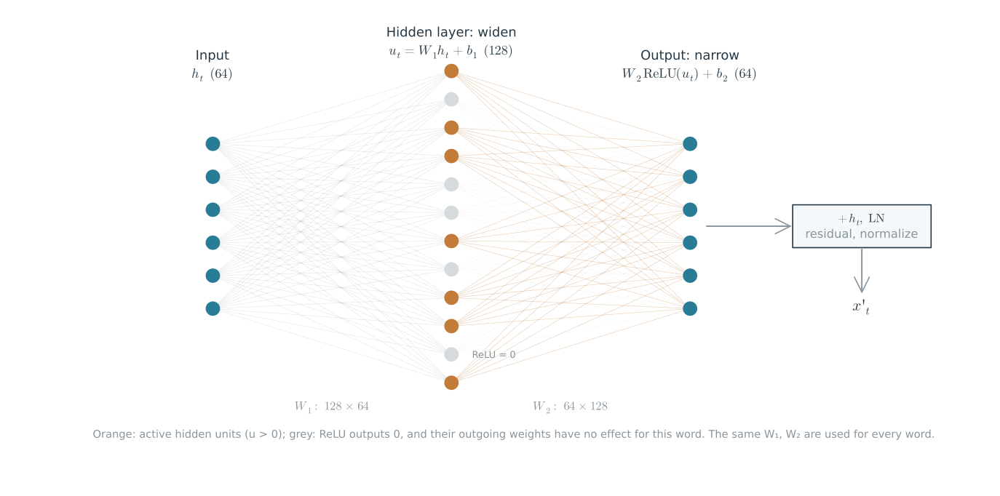

In [22]:
feedforward_diagram()

*Figure 19. The feedforward network for one word, drawn with 6, 12 and 6 units. Orange: active hidden units; grey: set to 0 by ReLU.*

### 3.7 Pooling, head, and "encoder only"

- Layer 2 attends to vectors that already contain context from layer 1.
- $a$ is the mean over real words, then the usual head. BERT uses the vector of a first token, `[CLS]`, instead of the mean.
- The translation Transformer also has a **decoder**, which writes text word by word: it masks future words (causal mask) and attends to the encoder.
  Classification only reads, so BERT and our model use the **encoder** alone. GPT-style models use the decoder alone.

### 3.8 Train the Transformer

The same training settings as the RNN, learning rate 0.002, on a GPU if available.
`TRAIN_TRANSFORMER=true` refits.

Epoch 1 | train 0.177 | validation 0.289 | val accuracy 87.8%
Epoch 2 | train 0.137 | validation 0.359 | val accuracy 85.9%
Epoch 3 | train 0.053 | validation 0.379 | val accuracy 86.8%
Epoch 4 | train 0.035 | validation 0.429 | val accuracy 86.2%
Epoch 5 | train 0.025 | validation 0.541 | val accuracy 86.3%
Epoch 6 | train 0.023 | validation 0.539 | val accuracy 86.4%
Epoch 7 | train 0.012 | validation 0.601 | val accuracy 86.5%
Epoch 8 | train 0.011 | validation 0.558 | val accuracy 86.1%
transformer: selected epoch 1 | test accuracy 85.70% | fit 172 seconds


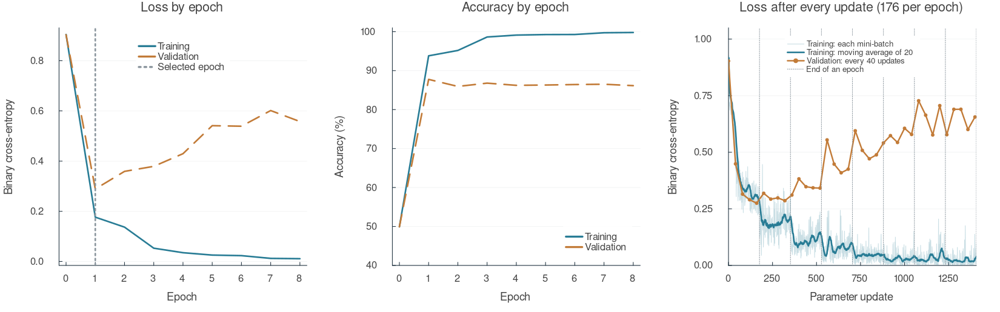

In [23]:
TRAIN_TRANSFORMER=false
transformer_run=fit_or_load("transformer",transformer_initial,imdb,RESULTS;lr=0.002f0,forward=transformer_forward,
    monitored=false,retrain=TRAIN_TRANSFORMER,device=gpu_or_cpu)
training_plot(transformer_run;loss_legend=:top)

*Figure 20. The Transformer fit, drawn like Figures 4 and 12.*

- **Fast:** the best validation loss comes at epoch 1. Every word reaches $a$ in $K=2$ steps, so there is no vanishing gradient.
- **Then overfitting:** training loss falls while validation loss rises; early stopping keeps epoch 1.

### 3.9 One sentence through the trained model

`transformer_trace` runs the trained model on "The movie is good, not bad." and keeps every intermediate result.

Transformer, P(positive) = 0.0054 | The movie is good, not bad.
Transformer, P(positive) = 0.0061 | The movie is bad, not good.


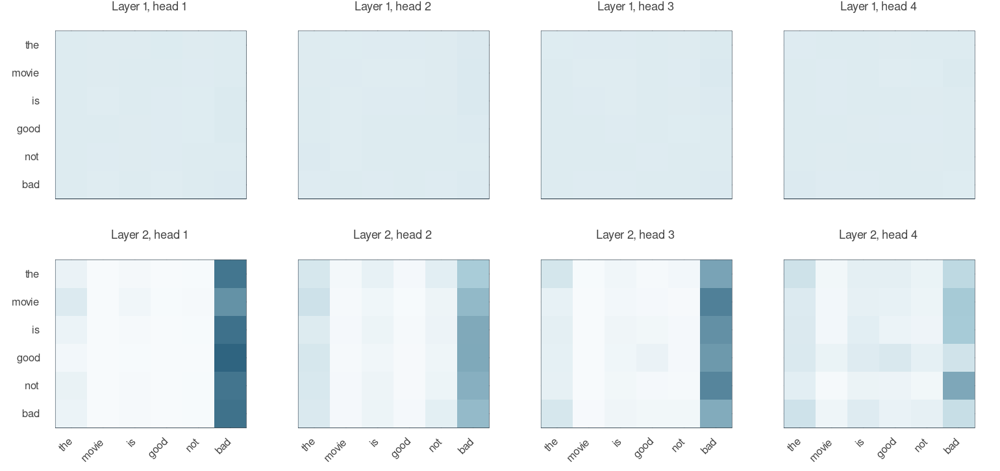

In [24]:
for s in my_reviews[3:4]
    @printf("Transformer, P(positive) = %.4f | %s\n",sentiment_probability(s,transformer_run),s)
end
sentence_trace=transformer_trace(my_reviews[3],transformer_run)
head_attention_plot(sentence_trace)

*Figure 21. Attention weights $\alpha^{(h)}_{ts}$ per layer and head. Row: the word that collects; column: the word it collects from. White 0, dark blue 1.*

- **Layer 1:** every head gives $\alpha_{ts}\approx1/T$ ($T=6$), so every word receives the same attention output:
$$
h_t=\mathrm{LN}\Big(\underbrace{\tilde e_t+p_t}_{\text{word }t\text{ and its position}}+\underbrace{W_O\big[\tfrac1T\textstyle\sum_s v^{(1)}_s;\ldots;\tfrac1T\sum_s v^{(4)}_s\big]+b_O}_{\text{average of the review, the same for every }t}\Big).
$$
  The average ignores order: it is unchanged if the words are permuted.
- **Layer 2:** heads 1–3 put most weight on "bad", wherever it stands.
- No head links "not" to "good", so both probes are judged negative.

In [25]:
for r in label_shares(imdb.training,["good","bad","great","awful","not good","not bad"])
    @printf("%-9s in %4.1f%% of training reviews, %4.1f%% of them positive
",r.phrase,100r.present,100r.positive)
end

good      in 38.6% of training reviews, 49.7% of them positive
bad       in 23.7% of training reviews, 25.7% of them positive
great     in 25.3% of training reviews, 66.8% of them positive
awful     in  5.7% of training reviews, 10.1% of them positive
not good  in  0.5% of training reviews, 22.6% of them positive
not bad   in  0.6% of training reviews, 42.6% of them positive


- "good" appears in positive and negative reviews alike, so on its own it predicts nothing; "bad" is a strong sign of a negative review.
- The model has found the strongest single word, and every word collects it. Reading "not bad" needs word order, and the phrase is in 0.6% of the reviews.

Neither layer attends by position. The only order information left is $p_t$ inside each word's own vector; Figure 22 checks whether $P$ learned any.

Relative change from the starting values: position vectors 0.11, word vectors 0.33


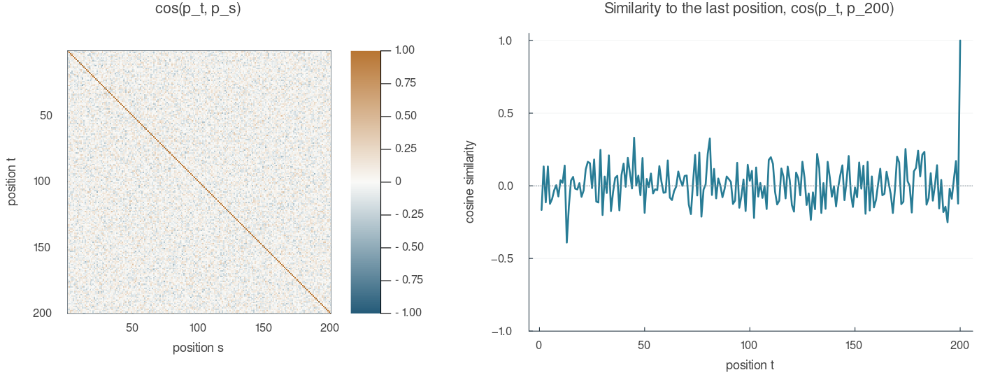

In [26]:
P0,P1=transformer_initial.P,transformer_run.model.P
@printf("Relative change from the starting values: position vectors %.2f, word vectors %.2f\n",
    norm(P1-P0)/norm(P0),norm(transformer_run.model.E-transformer_initial.E)/norm(transformer_initial.E))
position_similarity_plot(P1)

*Figure 22. Cosine similarity of the learned position vectors (left) and of each $p_t$ to the last position (right).*

- **Left:** 1 on the diagonal, about 0 everywhere else; neighbours $p_t,p_{t+1}$ are no more alike than distant positions.
- **Right:** only $p_{200}$ is similar to $p_{200}$.
- Random 64-dimensional vectors look exactly like this, and $P$ moved 11% from its random start against 33% for $E$.

The model learned no meaningful position information: it reads the review as a bag of words, with a test accuracy below the averaging model.

Layer 1: share of the 128 feedforward units active (u > 0), by word: 0.45, 0.48, 0.51, 0.51, 0.48, 0.43
Layer 2: share of the 128 feedforward units active (u > 0), by word: 0.43, 0.45, 0.41, 0.47, 0.41, 0.41


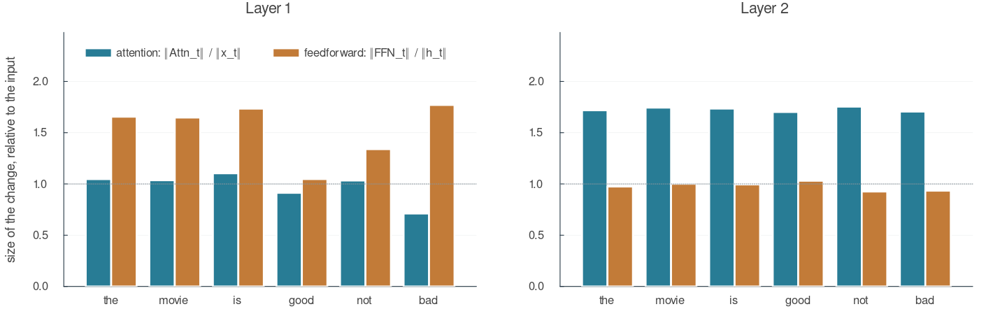

In [27]:
for (ℓ,layer) in enumerate(sentence_trace.layers)
    @printf("Layer %d: share of the 128 feedforward units active (u > 0), by word: %s\n",ℓ,
        join([@sprintf("%.2f",x) for x in layer.active],", "))
end
update_size_plot(sentence_trace)

*Figure 23. Relative size of each update: $\lVert\mathrm{Attn}_t\rVert/\lVert x_t\rVert$ and $\lVert f_t\rVert/\lVert h_t\rVert$, per word and layer.*

- Both parts change the vectors by about their own size; the residual keeps the input.
- In layer 2 the attention change is the same for every word: every word collects the same "bad"-dominated mix.

## 4. Pretrained BERT: learn the language first, then the task

All models so far learn word meanings and how to combine them from one label per review. Pretraining learns the language first, from unlabelled text:

$$
\begin{aligned}
\text{1. Pretraining:}&\quad \hat\theta_{\text{LM}}=\arg\min_\theta\ -\textstyle\sum_{t\in\mathcal M}\log P_\theta\big(x_t\mid\text{other tokens}\big) &&\text{hide 15\% of the tokens }(\mathcal M)\\
\text{2. Fine-tuning:}&\quad \text{start from }\hat\theta_{\text{LM}},\ \text{add the head, minimize the review loss}
\end{aligned}
$$

- Step 1 needs only raw text, so it can use billions of words.
- We download the result of step 1, `bert-base-uncased` (English books and Wikipedia), and run step 2.

### 4.1 The pretrained model

| | Our Transformer | `bert-base-uncased` |
|---|---|---|
| Layers $K$, width $d$, heads | 2, 64, 4 | 12, 768, 12 |
| Feedforward width, activation | 128, ReLU | 3,072, GELU |
| Vocabulary | 20,000 words | 30,522 word pieces |
| Starting values | random | pretrained |

**Special tokens.** The vocabulary also holds entries that are not text, each with its own learned vector in $E$:

- `[CLS]` (classification) starts every input. Its last vector $x^{(12)}_1$ can collect from all tokens through attention; in pretraining a head read it to predict whether two sentences follow each other. We average all tokens instead, as in our other models.
- `[SEP]` (separator) ends a text. Two texts are read as `[CLS]` A `[SEP]` B `[SEP]`, and a segment vector marks which text each token belongs to: $S_A$ for A, $S_B$ for B. A review is one text, so $S=S_A$ for every token.
- `[PAD]` fills the input up to its fixed length and is masked; `[MASK]` replaces the hidden words in pretraining.

We keep this format because it is what the model saw in pretraining. The input vector of token $t$ is $\mathrm{LN}(E[:,x_t]+P[:,t]+S)$; the head is new and random.

BERT parameters: 108940161 (85 times the averaging model)
  embedding tables 23836416 | 12 layers 85054464 | new head 49281


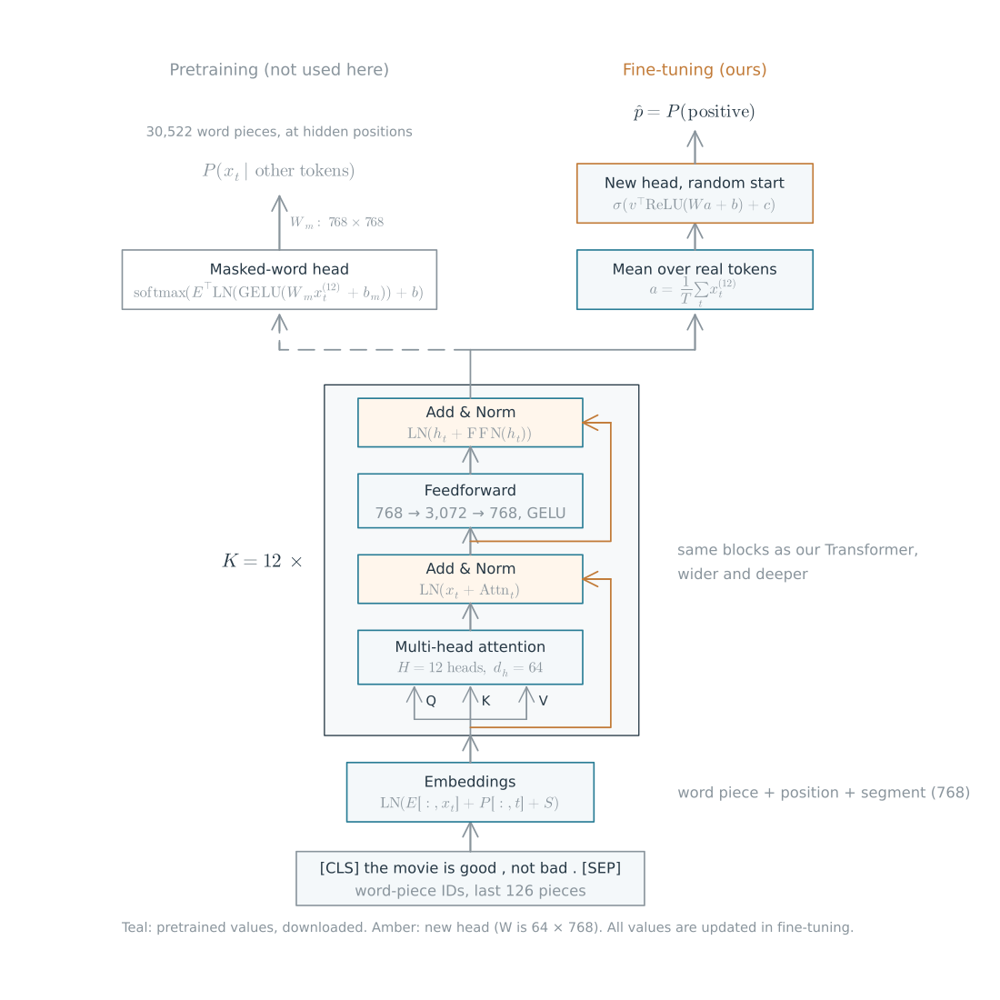

In [28]:
bert_initial=bert_model()
@printf("BERT parameters: %d (%.0f times the averaging model)\n",parameter_count(bert_initial),
    parameter_count(bert_initial)/parameter_count(classifier_initial))
@printf("  embedding tables %d | 12 layers %d | new head %d\n",
    sum(length,(bert_initial.E,bert_initial.P,bert_initial.S,bert_initial.ge,bert_initial.βe)),
    parameter_count(bert_initial.layers),sum(length,(bert_initial.W,bert_initial.b,bert_initial.v,bert_initial.c)))
bert_architecture_diagram()

*Figure 24. `bert-base-uncased` with its pretraining head (left, not used) and our head (right). Teal: downloaded values; amber: new.*

- **Body:** 12 encoder layers of the same form as our Transformer; each word piece leaves as a 768-vector $x^{(12)}_t$.
- **Pretraining head:** predicts the hidden word pieces from $x^{(12)}_t$. We drop it, and the next-sentence head on `[CLS]`.
- **Our head:** the same mean and head as in all our models, now with $W\in\mathbb R^{64\times768}$.
- Fine-tuning updates all values, the body included.

Most parameters now sit in the layers, not in the embedding table.

### 4.2 Word pieces

- **Vocabulary:** 30,522 entries in a fixed order; a token's ID is its row in $E$. The first 104 are reserved: `[PAD]`, unused slots, `[UNK]`, `[CLS]`, `[SEP]`, `[MASK]`. The rest are characters, whole words and word pieces.
- **Splitting:** a word not in the vocabulary is split into the longest pieces that are; `##` marks a piece that continues a word. Only characters outside the vocabulary become `[UNK]`.
- **Input:** `[CLS]`, the word pieces, `[SEP]`, then `[PAD]` up to $T=128$ tokens. We keep the **last 126 word pieces**.

**Why 128.** BERT can read up to 512 tokens, the number of position vectors in $P$. But attention scores every pair of tokens, and training keeps all scores for the backward pass. Each update uses a batch of 8 reviews, each with its own scores:

$$
\begin{aligned}
S&=QK^\top\in\mathbb R^{T\times T} &&\text{one score } q_t^\top k_s \text{ per pair of tokens}\\
\text{scores per update}&=\underbrace{12}_{\text{heads}}\times\underbrace{12}_{\text{layers}}\times\underbrace{8}_{\text{reviews per batch}}\times T^2 &&\text{grows with } T^2\\
T=128:&\quad 1.9\times10^{7},\qquad T=512:\quad 3.0\times10^{8}\ \ (16\times)
\end{aligned}
$$

Everything else (word vectors, feedforward layers) grows only like $T$. Four times the length therefore costs sixteen times the memory for attention, and 128 tokens is what fits on our GPU.

In [29]:
bert_vocabulary=bert_vocab_cached()
for t in ["[PAD]","[UNK]","[CLS]","[SEP]","[MASK]"]
    @printf("%-7s ID %3d\n",t,bert_id(bert_vocabulary,t))
end
for s in ["unaffable","The movie is good, not bad.",my_reviews[2]]
    println("\n",s,"\n  → ",join(bert_tokens(s,bert_vocabulary)," "))
end
X_example=bert_inputs(["The movie is good, not bad."],bert_vocabulary;L=14)
println("\nInput IDs with L = 14:\n  ",join(["$(bert_vocabulary.tokens[i])=$i" for i in X_example[:,1]]," "))
imdb=merge(imdb,(training=add_bert_inputs(imdb.training,bert_vocabulary),
    validation=add_bert_inputs(imdb.validation,bert_vocabulary),test=add_bert_inputs(imdb.test,bert_vocabulary)))
@printf("\nInput matrix for the training split: %d × %d; %.0f%% of reviews are longer than 126 tokens\n",
    size(imdb.training.B)...,100mean(imdb.training.B[end,:].!=bert_id(bert_vocabulary,"[PAD]")))

[PAD]   ID   1
[UNK]   ID 101
[CLS]   ID 102
[SEP]   ID 103
[MASK]  ID 104



unaffable
  → una ##ffa ##ble

The movie is good, not bad.
  → the movie is good , not bad .

The plot was confusing and the dialogue was painfully dull.
  → the plot was confusing and the dialogue was painfully dull .



Input IDs with L = 14:
  [CLS]=102 the=1997 movie=3186 is=2004 good=2205 ,=1011 not=2026 bad=2920 .=1013 [SEP]=103 [PAD]=1 [PAD]=1 [PAD]=1 [PAD]=1



Input matrix for the training split: 128 × 22411; 88% of reviews are longer than 126 tokens


### 4.3 What pretraining learned

Hide a word with `[MASK]` and ask the pretrained model, with its original prediction head (left in Figure 24), for

$$
P(x_t\mid\text{other tokens})=\mathrm{softmax}\big(E^\top\mathrm{LN}(\mathrm{GELU}(W_mx^{(12)}_t+b_m))+b\big),\qquad W_m\in\mathbb R^{768\times768}:
$$

one hidden layer, then a dot product with every word-piece vector in $E$.

In [30]:
mlm=bert_mlm_head()
for s in ["The capital of France is [MASK].","He went to the [MASK] to buy some milk.",
          "The movie was [MASK], I loved every minute of it.","The movie was [MASK], I want my money back."]
    guesses=fill_mask(s,bert_initial,mlm,bert_vocabulary)
    println(s,"\n  → ",join([@sprintf("%s (%.2f)",w,q) for (w,q) in guesses],", "))
end

The capital of France is [MASK].
  → paris (0.42), lille (0.07), lyon (0.06), marseille (0.04), tours (0.03)
He went to the [MASK] to buy some milk.
  → store (0.38), fridge (0.14), kitchen (0.10), refrigerator (0.06), supermarket (0.04)
The movie was [MASK], I loved every minute of it.
  → great (0.24), amazing (0.18), fantastic (0.08), good (0.06), incredible (0.05)
The movie was [MASK], I want my money back.


  → good (0.20), great (0.13), bad (0.07), over (0.06), terrible (0.03)


- Facts, everyday knowledge and grammar: Paris, store, an adjective after "The movie was".
- Context shapes the guess: "I loved every minute" makes positive adjectives likely.
- But "I want my money back" still gets "good" first. Pretraining learns which words are likely, not sentiment; that comes from the labels.

### 4.4 Fine-tune on the reviews

- Start from the pretrained values; only the head is random.
- Learning rate $2\times10^{-5}$, a hundred times smaller than for our Transformer, to stay close to the pretrained values.
- Batch 8, 3 epochs; each layer is recomputed in the backward pass to fit the GPU memory. About one hour on a GPU; `TRAIN_BERT=true` refits.

selected epoch 1 | fit 62 minutes


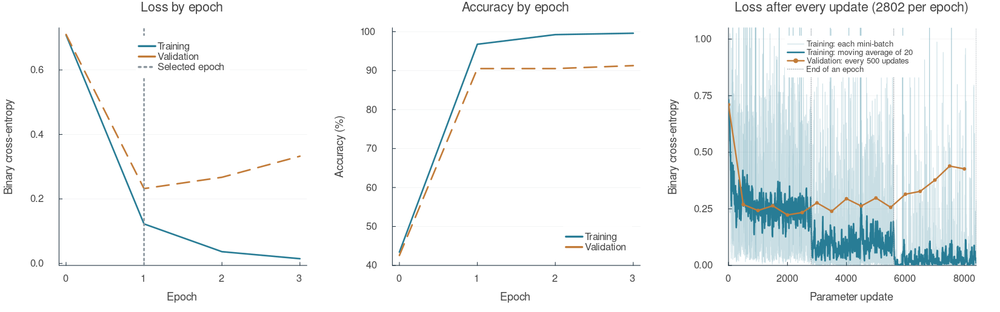

In [31]:
TRAIN_BERT=false
bert_path=joinpath(RESULTS,"bert_finetuned.jls")
bert_run=if TRAIN_BERT || !isfile(bert_path)
    recompute_forward(m,X)=bert_forward(m,X;checkpoint=true)
    fit=train_reviews(imdb,bert_initial;epochs=3,batch_size=8,lr=2f-5,clip=1f0,eval_every=500,eval_batch=32,
        forward=recompute_forward,input=:B,budget=6*3600,device=gpu_or_cpu())
    fit=merge(fit,(; initial=nothing))   # the pretrained start is re-read from model.safetensors
    serialize(bert_path,fit); fit
else
    deserialize(bert_path)
end
@printf("selected epoch %d | fit %.0f minutes\n",bert_run.best_epoch,bert_run.seconds/60)
training_plot(bert_run;loss_legend=:top)

*Figure 25. The BERT fit, drawn like Figures 4, 12 and 20. One epoch is 2,802 updates of 8 reviews.*

- **Fast:** validation loss reaches about its final level within a few hundred updates; the model already knows the language.
- **Then memorization:** training loss drops at each new epoch while validation loss rises. Selection keeps epoch 1.

### 4.5 What fine-tuning changed

The probe sentences; how far the values moved, for a weight matrix $W$:

$$
\frac{\lVert W_{\text{fine-tuned}}-W_{\text{pretrained}}\rVert}{\lVert W_{\text{pretrained}}\rVert},\qquad \lVert W\rVert=\Big(\textstyle\sum_{ij}W_{ij}^2\Big)^{1/2};
$$

then the fill-in test from above with the fine-tuned body (the masked-word head is not refitted):

In [32]:
for s in my_reviews
    @printf("BERT, P(positive) = %.4f | %s\n",sentiment_probability(s,bert_run),s)
end
rel(a,b)=norm(a-b)/norm(b)
@printf("\nRelative change in fine-tuning: word vectors %.3f | layer 1 W_Q %.3f | layer 12 W_1 %.3f\n",
    rel(bert_run.model.E,bert_initial.E),rel(bert_run.model.layers[1].Wq,bert_initial.layers[1].Wq),
    rel(bert_run.model.layers[12].W1,bert_initial.layers[12].W1))
for s in ["The capital of France is [MASK].","He went to the [MASK] to buy some milk.",
          "The movie was [MASK], I loved every minute of it.","The movie was [MASK], I want my money back."]
    println("\n",s)
    for (name,m) in (("before",bert_initial),("after",bert_run.model))
        guesses=fill_mask(s,m,mlm,bert_vocabulary)
        println("  ",rpad(name,7),"→ ",join([@sprintf("%s (%.2f)",w,q) for (w,q) in guesses],", "))
    end
end

BERT, P(positive) = 0.9950 | The actors were wonderful and the story kept me interested.
BERT, P(positive) = 0.0075 | The plot was confusing and the dialogue was painfully dull.


BERT, P(positive) = 0.9035 | The movie is good, not bad.


BERT, P(positive) = 0.0327 | The movie is bad, not good.

Relative change in fine-tuning: word vectors 0.014 | layer 1 W_Q 0.025 | layer 12 W_1 0.022

The capital of France is [MASK].


  before → paris (0.42), lille (0.07), lyon (0.06), marseille (0.04), tours (0.03)
  after  → paris (0.60), lille (0.06), lyon (0.05), brest (0.03), nancy (0.02)

He went to the [MASK] to buy some milk.
  before → store (0.38), fridge (0.14), kitchen (0.10), refrigerator (0.06), supermarket (0.04)
  

after  → store (0.22), kitchen (0.22), market (0.08), bathroom (0.08), bank (0.04)

The movie was [MASK], I loved every minute of it.
  before → great (0.24), amazing (0.18), fantastic (0.08), good (0.06), incredible (0.05)
  after  → unique (0.03), beautiful (0.03), continuous (0.03), wonderful (0.03), passionate (0.02)

The movie was [MASK], I want my money back.


  before → good (0.20), great (0.13), bad (0.07), over (0.06), terrible (0.03)
  after  → lost (0.09), cancelled (0.06), bad (0.05), banned (0.03), ruined (0.03)


- **Negation:** "good, not bad" is positive and "bad, not good" negative; unlike all earlier models, BERT reads the order.
- **Small move:** the values change by about 2%. The small learning rate keeps what pretraining learned: Paris and store still come first.
- **Sentiment enters the body:** for "I want my money back" the guesses turn from good to lost, cancelled, bad. The labels changed the vectors $x^{(12)}_t$, not only the head.
- **Flatter guesses** for "I loved every minute": the masked-word head was fitted to the old vectors and reads the new ones less sharply.

The same comparison for the attention weights of the 144 heads (12 layers × 12 heads) and for the position vectors:

Average change by layer: 0.07 0.14 0.13 0.17 0.24 0.18 0.19 0.20 0.30 0.55 0.63 0.55


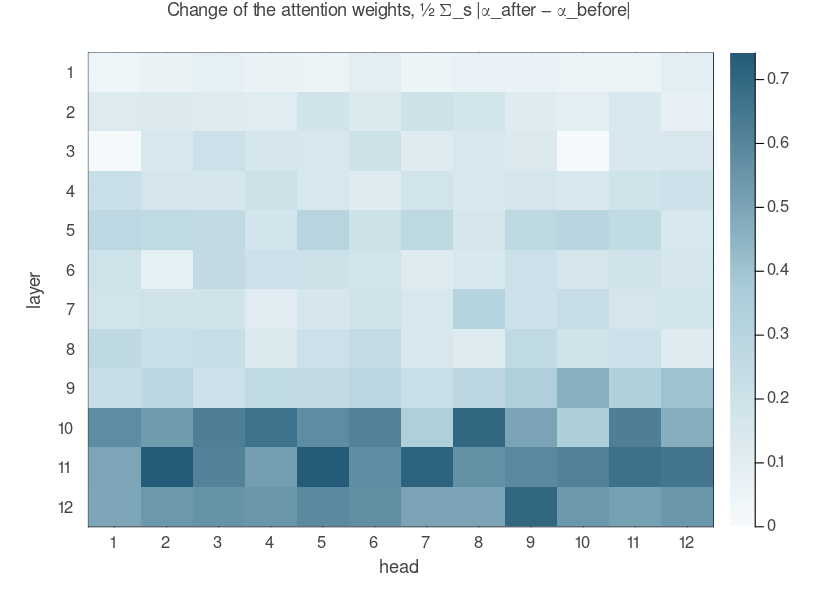

In [33]:
head_change=bert_head_change(bert_initial,bert_run.model,[r.text for r in imdb.validation.rows[1:16]],bert_vocabulary)
println("Average change by layer: ",join([@sprintf("%.2f",x) for x in vec(mean(head_change;dims=2))]," "))
bert_head_change_plot(head_change)

*Figure 26. Change of each head in fine-tuning: $\tfrac12\sum_s\lvert\alpha^{\text{after}}_{ts}-\alpha^{\text{before}}_{ts}\rvert$, 0 for the same weights and 1 for no overlap, averaged over the tokens $t$ of 16 validation reviews.*

- **Layers 1–9 change little:** they keep what pretraining learned.
- **Layers 10–12 change most:** the top of the body is rebuilt for the task.

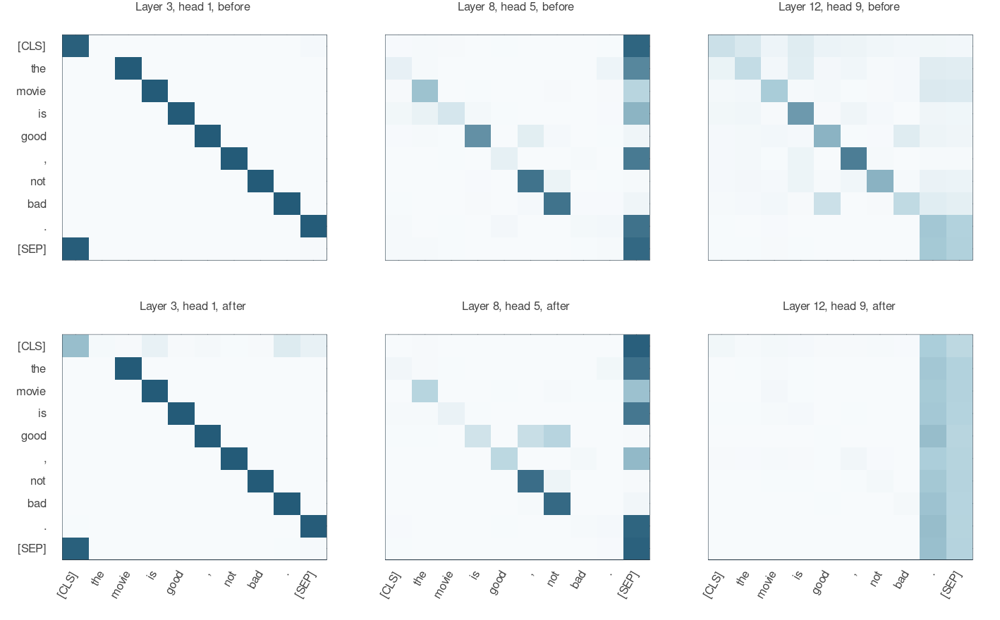

In [34]:
probe=my_reviews[3]
bert_attention_compare_plot(bert_attention(probe,bert_initial,bert_vocabulary),
    bert_attention(probe,bert_run.model,bert_vocabulary),[(3,1),(8,5),(12,9)])

*Figure 27. Three heads on "The movie is good, not bad.", before (top) and after (bottom) fine-tuning. Row: the token that collects; column: the token it collects from.*

- **Layer 3, head 1:** every token collects from the next one, so "not" collects from "bad".
- **Layer 8, head 5:** every token collects from the previous one, so "bad" collects from "not". Tokens with nothing to collect put their weight on `[SEP]`.
- Both heads come from pretraining and barely change. By layer 8 the vector at "bad" already carries "not bad"; the top layers read these combined vectors.
- **Layer 12, head 9**, the head that changed most on this sentence: before, every token collected from itself; after, every token collects from "." and `[SEP]`.
- Our Transformer has no head that links "not" and "bad".

**Why these two patterns mean "nothing to collect".** The weights of a head sum to one, $\sum_s\alpha_{ts}=1$, so a head cannot switch itself off; it must put its weight somewhere harmless.

- **On itself** (the diagonal): the head adds $W_OW_Vx_t$. This does change $x_t$, but only through a linear map of the token's own vector, the kind of per-token change the feedforward layer also makes. What only attention can do, moving information between tokens, does not happen.
- **On "." and `[SEP]`:** they appear at the end of every input, and by the top layers their vectors are small. The head adds the same small vector to every token, so almost nothing changes. The next cell measures what each token can add through this head, $\lVert W_Ov_s\rVert$:

In [35]:
vs=bert_value_sizes(probe,bert_run.model,bert_vocabulary,12,9)
for (t,v,x) in zip(vs.tokens,vs.value,vs.input)
    @printf("%-6s ‖W_O v_s‖ = %5.2f   ‖x_s‖ = %5.2f
",t,v,x)
end

[CLS]  ‖W_O v_s‖ =  6.16   ‖x_s‖ = 19.50
the    ‖W_O v_s‖ =  5.75   ‖x_s‖ = 21.02
movie  ‖W_O v_s‖ =  5.04   ‖x_s‖ = 20.19
is     ‖W_O v_s‖ =  5.59   ‖x_s‖ = 21.17
good   ‖W_O v_s‖ =  6.73   ‖x_s‖ = 21.41
,      ‖W_O v_s‖ =  6.56   ‖x_s‖ = 21.20
not    ‖W_O v_s‖ =  7.22   ‖x_s‖ = 20.84
bad    ‖W_O v_s‖ =  7.74   ‖x_s‖ = 20.47
.      ‖W_O v_s‖ =  0.21   ‖x_s‖ =  4.26
[SEP]  ‖W_O v_s‖ =  0.77   ‖x_s‖ =  4.55


"." and `[SEP]` can add about a tenth of what a word can add: attending to them leaves the tokens almost unchanged.

Relative change of p_t: positions 1–128 0.054 on average, positions 129–512 0.000 at most


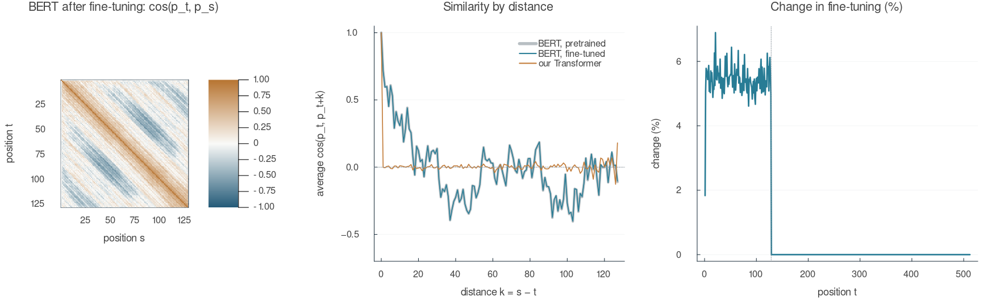

In [36]:
r_pos=vec(sqrt.(sum(abs2,bert_run.model.P.-bert_initial.P;dims=1))./sqrt.(sum(abs2,bert_initial.P;dims=1)))
@printf("Relative change of p_t: positions 1–128 %.3f on average, positions 129–512 %.3f at most\n",
    mean(r_pos[1:128]),maximum(r_pos[129:end]))
bert_position_plot(bert_initial.P,bert_run.model.P,transformer_run.model.P)

*Figure 28. BERT's position vectors. Left: $\cos(p_t,p_s)$ after fine-tuning, first 128 positions. Middle: average $\cos(p_t,p_{t+k})$ by distance $k$. Right: change of each $p_t$ in fine-tuning.*

- **Pretraining built structure:** neighbouring positions are similar (cosine about 0.6 up to $k\approx10$), with waves at larger distances. Our Transformer's position vectors stayed unrelated: 0 for every $k\neq0$.
- **Fine-tuning kept it:** the pretrained and fine-tuned curves lie on top of each other; each $p_t$ moved about 5%.
- **Positions 129–512 did not move:** our inputs never reach them, so they get no gradient.

## 5. Compare all models

In [37]:
avg_last=evaluate_reviews(sentiment.model,last_words(imdb.test,L_seq,V_review))
rows=[("Averaging (all words)",sentiment.model,sentiment.test,sentiment.seconds),
      ("Averaging, evaluated on last 200 words",sentiment.model,avg_last,NaN),
      ("RNN, learning rate 0.002",rnn_base.model,rnn_base.test,rnn_base.seconds),
      ("RNN, learning rate 0.0005",rnn_run.model,rnn_run.test,rnn_run.seconds),
      ("LSTM (last 200 words)",lstm_run.model,lstm_run.test,lstm_run.seconds),
      ("Transformer (last 200 words)",transformer_run.model,transformer_run.test,transformer_run.seconds),
      ("BERT, fine-tuned (last 126 tokens)",bert_run.model,bert_run.test,bert_run.seconds)]
@printf("%-40s %11s %9s %8s %8s %8s\n","Model","Params","Accuracy","F1","Loss","Train (s)")
for (name,m,r,sec) in rows
    @printf("%-40s %11d %8.2f%% %8.4f %8.4f %8s\n",name,parameter_count(m),100r.accuracy,r.f1,r.loss,
        isnan(sec) ? "—" : @sprintf("%.0f",sec))
end
println()
runs=[("Averaging",sentiment),("RNN",rnn_run),("LSTM",lstm_run),("Transformer",transformer_run),("BERT",bert_run)]
@printf("%-66s%s\n","P(positive)",join([lpad(n,12) for (n,_) in runs]))
for s in [my_reviews;"The first half is boring, but the ending is wonderful and moving."]
    @printf("%-66s%s\n",s,join([@sprintf("%12.4f",sentiment_probability(s,r)) for (_,r) in runs]))
end

Model                                         Params  Accuracy       F1     Loss Train (s)


Averaging (all words)                        1284225    87.78%   0.8730   0.2969       12
Averaging, evaluated on last 200 words       1284225    86.87%   0.8634   0.3091        —
RNN, learning rate 0.002                     1292481    82.54%   0.8226   0.4080      214
RNN, learning rate 0.0005                    1292481    84.75%   0.8504   0.4014      199
LSTM (last 200 words)                        1317249    84.65%   0.8370   0.3614      789
Transformer (last 200 words)                 1363585    85.70%   0.8474   0.3283      172


BERT, fine-tuned (last 126 tokens)         108940161    91.21%   0.9088   0.2183     3738



P(positive)                                                          Averaging         RNN        LSTM Transformer        BERT


The actors were wonderful and the story kept me interested.             0.9980      0.8363      0.7744      0.9760      0.9950


The plot was confusing and the dialogue was painfully dull.             0.0000      0.0409      0.0281      0.0046      0.0075


The movie is good, not bad.                                             0.0003      0.3278      0.3352      0.0054      0.9035


The movie is bad, not good.                                             0.0003      0.4145      0.3456      0.0061      0.0327


The first half is boring, but the ending is wonderful and moving.       0.1427      0.7446      0.6597      0.1168      0.9665


Train (s): seconds to fit the model, evaluations included; the averaging model, RNN and LSTM on a CPU, the Transformer and BERT on a GPU.

**Accuracy.**

- BERT is the only model above the averaging model: 91.21% against 87.78%, while reading the fewest tokens.
- Truncation explains little: on the same last 200 words the averaging model still reaches 86.87%.
- The models trained from scratch stay 2 to 5 points below it. They must learn word meanings and how to combine them from the same 22,411 labels, and they are harder to optimize: the learning rate alone moved the RNN by 2.2 points.
- In IMDb, which words appear carries most of the signal; word order matters only in a minority of reviews (negation, contrast).

**Probes.**

- "good, not bad" against "bad, not good": averaging gives both the same probability; the RNN, LSTM and Transformer separate them a little but judge both negative. Only BERT gets both right.
- "boring … but the ending is wonderful": the recurrent models and BERT follow the ending; averaging and our Transformer weigh "boring" and stay negative.

The labelled data are the same for every model. What changed is the starting point:
BERT learned word meanings and how to combine them from unlabelled text, so the labels only had to teach the task.

**Reading the two probes word by word.** Each model is applied to the sentence up to and including each word (for the RNN and LSTM this is the head applied to $s_t$):

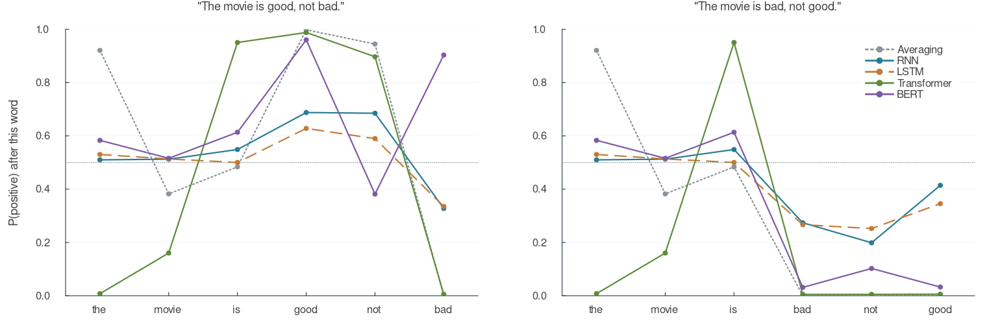

In [38]:
prefix_plot(my_reviews[3:4],[("Averaging",sentiment),("RNN",rnn_run),("LSTM",lstm_run),
    ("Transformer",transformer_run),("BERT",bert_run)])

*Figure 29. P(positive) after each word of the two probe sentences, for every model.*

- **Averaging** ends at the same value for both sentences: the last prefix holds the same words.
- **RNN and LSTM** follow the latest sentiment word: "bad" pulls them down, "good" up; "not" changes almost nothing.
- **Our Transformer** drops to 0 as soon as "bad" appears and stays there in both sentences.
- **BERT** reads the negation. In the first sentence it drops at "not" and rises to 0.90 at "bad"; in the second, "not good" stays negative.

## 6. A language model: predict the next token

A **language model** gives, at every position $t$, a distribution over the next token, and is trained to make the text it reads likely:

$$
P_\theta(x_{t+1}\mid x_1,\ldots,x_t)=\mathrm{softmax}\big(E^\top h_t\big),
\qquad
\mathcal L(\theta)=-\frac{1}{BT}\sum_{b=1}^{B}\sum_{t=1}^{T}\log P_\theta\big(x^{(b)}_{t+1}\mid x^{(b)}_{1},\ldots,x^{(b)}_{t}\big).
$$

- **No labels:** the text is its own target.
- **Generation:** draw $x_{t+1}\sim P_\theta(\cdot\mid x_1,\ldots,x_t)$, append it, repeat.
- **Two stages:** pretraining on raw text (this section: 11 million parameters from random values, on children's stories); post-training on instructions and answers (next section: a pretrained model of 135 million parameters).

### 6.1 Data: TinyStories

About 2.7 million short stories written by GPT-4 with the words of a 3- to 4-year-old (Eldan and Li, 2023): a small vocabulary, but full grammar and simple plots.

- **Text:** 2.2 GB for training; 22 MB of other stories for validation.
- **Token stream:** each story is encoded, followed by `<|endoftext|>`, and all stories are concatenated.

In [39]:
lm_data=tinystories_data()   # tokenizer and token streams; built once, then read from cached files
lm_tok=lm_data.tok
example=read_stories(joinpath(TINYSTORIES_DIR,"TinyStoriesV2-GPT4-valid.txt");n=2)[2]   # the file starts with the end of a story
@printf("Training stream: %.1f million tokens | validation stream: %.1f million tokens\n",
    length(lm_data.train)/1e6,length(lm_data.val)/1e6)
println("\nA validation story:\n",example)

Training stream: 552.7 million tokens | validation stream: 5.6 million tokens

A validation story:
Once upon a time, in a warm and sunny place, there was a big pit. A little boy named Tom liked to play near the pit. One day, Tom lost his red ball. He was very sad.
Tom asked his friend, Sam, to help him search for the ball. They looked high and low, but they could not find the ball. Tom said, "I think my ball fell into the pit."
Sam and Tom went close to the pit. They were scared, but they wanted to find the red ball. They looked into the pit, but it was too dark to see. Tom said, "We must go in and search for my ball."
They went into the pit to search. It was dark and scary. They could not find the ball. They tried to get out, but the pit was too deep. Tom and Sam were stuck in the pit. They called for help, but no one could hear them. They were sad and scared, and they never got out of the pit.


### 6.2 Tokens: byte-pair encoding

Every text is a sequence of bytes, so it can always be encoded; frequent byte sequences become single tokens.
On a sample of text split into chunks (a word with its leading space, a number, or punctuation):

$$
\mathcal V_0=\{256\ \text{bytes}\},\qquad
(a^\ast,b^\ast)=\arg\max_{(a,b)}\ \#\{\text{adjacent }a\,b\text{ in the chunks}\},\qquad
\mathcal V_{m+1}=\mathcal V_m\cup\{a^\ast b^\ast\},
$$

repeated until the vocabulary is full. A new text is encoded by applying the merges in the order learned.

- **Ours:** learned on 30,000 stories; $4{,}096=256$ bytes $+\ 3{,}839$ merges $+$ `<|endoftext|>`.
- **No unknown token:** a new word is split into known pieces, at worst single bytes.
- **Leading space:** `" dog"` and `"dog"` are different tokens.

In [40]:
piece(t)=repr(symbols_to_text(t))
println("First 15 merges: ",join(piece.(lm_tok.tokens[257:271]),"  "))
println("Last 10 merges:  ",join(piece.(lm_tok.tokens[end-10:end-1]),"  "))
println()
for s in ["Once upon a time, there was a little dog named Spot.","The astronaut photographed Saturn's rings."]
    println(join(repr.(bpe_pieces(s,lm_tok))," "))
end
@printf("\nCharacters per token in this story: %.2f\n",length(example)/length(bpe_encode(example,lm_tok)))

First 15 merges: " t"  "he"  " a"  " s"  " w"  "nd"  " the"  "ed"  " b"  " to"  " and"  " h"  " f"  "in"  " T"
Last 10 merges:  "'d"  "ctopus"  "ention"  " anywhere"  " bin"  " battery"  " bookshe"  " dive"  " gasped"  " resist"



"Once" " upon" " a" " time" "," " there" " was" " a" " little" " dog" " named" " Spot" "."
"The" " a" "st" "ron" "aut" " ph" "ot" "og" "ra" "p" "hed" " S" "at" "urn" "'s" " r" "ings" "."

Characters per token in this story: 3.87


- **First merges:** the most frequent pairs, pieces of ` the` and ` and`. **Last merges:** whole, less frequent words.
- **Rare words** (`astronaut`, `Saturn`) are split into pieces; 3.87 characters per token on average.

### 6.3 The model: a decoder

$x_t\in\mathbb R^{d}$ is the vector at position $t$ (the **residual stream**); it starts as the token's column of $E$ and is changed only by adding to it:

$$
\begin{aligned}
x_t&\leftarrow E[:,x_t] &&\text{token vector; no position vector}\\
x_t&\leftarrow x_t+\mathrm{Attn}_t\big(\mathrm{RMSNorm}(x_1),\ldots,\mathrm{RMSNorm}(x_t)\big) &&\text{causal attention with RoPE and grouped heads}\\
x_t&\leftarrow x_t+\mathrm{FFN}\big(\mathrm{RMSNorm}(x_t)\big) &&\text{SwiGLU feedforward; both steps in each of }K=6\text{ layers}\\
P(x_{t+1}=j\mid x_1,\ldots,x_t)&=\mathrm{softmax}\big(E^\top\mathrm{RMSNorm}(x_t)\big)_j &&\text{output head: the same table }E
\end{aligned}
$$

The blocks of the Transformer classifier, with six changes shared by current open models (LLaMA, Qwen, SmolLM2), one subsection each:
causal mask, RoPE, grouped-query attention, RMSNorm before each block, SwiGLU, tied output head.

Token table E: 1572864 | one layer: 1573632 | 6 layers: 9441792 | total: 11015040 parameters


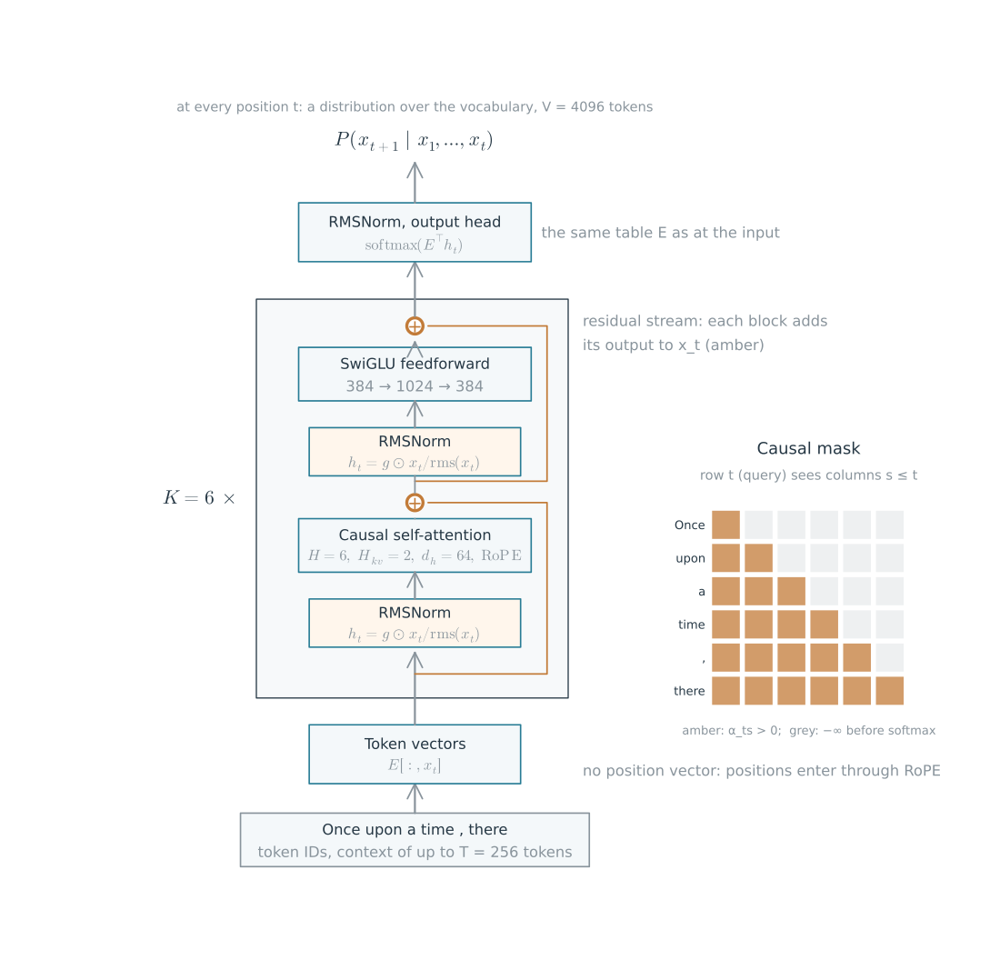

In [41]:
lm_cfg=gpt_config(;V=length(lm_tok.tokens),d=384,layers=6,heads=6,kv_heads=2,ff=1024)
lm_initial=gpt_model(lm_cfg)
per_layer=n_params(lm_initial.layers[1])
@printf("Token table E: %s | one layer: %s | %d layers: %s | total: %s parameters\n",
    length(lm_initial.E),per_layer,lm_cfg.layers,lm_cfg.layers*per_layer,n_params(lm_initial))
decoder_architecture_diagram(lm_cfg)

*Figure 30. The decoder trained in this section. Left: one layer (repeated $K=6$ times) adds the outputs of attention and of the feedforward network to the residual stream $x_t$ (amber); each block reads a normalized copy. Right: the causal mask.*

- **Sizes:** $T=256$ tokens of context, $V=4{,}096$, $d=384$, $H=6$ heads of $d_h=64$, $K=6$ layers.
- **One layer:** $W_Q,W_O\in\mathbb R^{384\times384}$, $W_K,W_V\in\mathbb R^{128\times384}$, $W_1,W_3\in\mathbb R^{1024\times384}$, $W_2\in\mathbb R^{384\times1024}$. In total 9.4 million values in the layers, 1.6 million in $E$.

### 6.4 Causal self-attention

Position $t$ must not see its target $x_{t+1}$:

$$
A=\mathrm{softmax}_{\text{rows}}\Big(\frac{QK^\top}{\sqrt{d_h}}+M\Big),\qquad
M_{ts}=\begin{cases}0,& s\le t\\-\infty,& s>t\end{cases}
\quad\Longrightarrow\quad \alpha_{ts}=0\ \text{for } s>t,\qquad \sum_{s\le t}\alpha_{ts}=1 .
$$

- **In every layer,** $x_t$ depends only on $x_1,\ldots,x_t$: each layer reads the previous one at positions $s\le t$.
- **Generation:** a new token adds a row to $A$ and changes no earlier row, so earlier keys and values are computed once and stored.

**Every position is a training example:** one window of $T+1$ tokens gives $T$ predictions, in one pass.

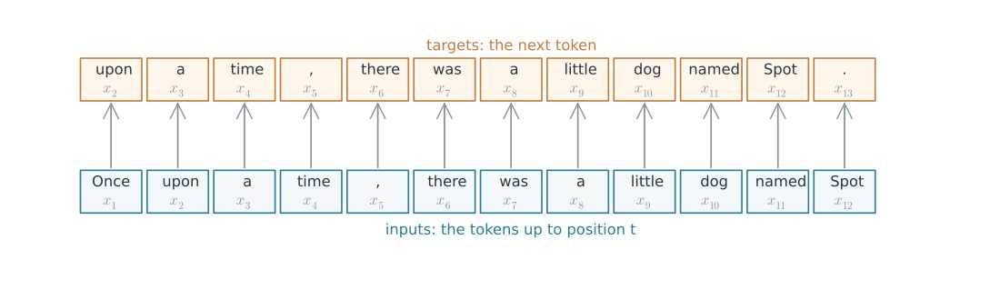

In [42]:
next_token_diagram(bpe_pieces("Once upon a time, there was a little dog named Spot.",lm_tok))

*Figure 31. One window of 13 tokens. The model reads $x_1,\ldots,x_{12}$ (teal) and at position $t$ predicts $x_{t+1}$ (amber): 12 examples from one sentence.*

### 6.5 Positions: rotary embedding (RoPE)

Attention ignores order unless positions enter. RoPE (Su et al., 2021) rotates the query and the key of each head by angles proportional to their positions.
A head's query has $d_h=64$ coordinates ($W_Q$ maps the 384 of $x_t$ to 6 heads of 64; $x_t$ itself is not rotated), taken as 32 pairs $(q_i,q_{i+32})$:

$$
\begin{pmatrix}q'_i\\ q'_{i+32}\end{pmatrix}=
\underbrace{\begin{pmatrix}\cos t\theta_i&-\sin t\theta_i\\ \sin t\theta_i&\cos t\theta_i\end{pmatrix}}_{\text{rotation by }t\theta_i}
\begin{pmatrix}q_i\\ q_{i+32}\end{pmatrix},
\qquad \theta_i=10{,}000^{-2(i-1)/64},\quad i=1,\ldots,32,
$$

and the key at position $s$ by $s\theta_i$. With $R_t$ the rotation of all 32 pairs,

$$
(R_tq_t)^\top(R_sk_s)=q_t^\top\underbrace{R_t^\top R_s}_{=\,R_{s-t}}k_s=q_t^\top R_{s-t}\,k_s .
$$

- **Relative position:** the score depends on $q_t$, $k_s$ and $s-t$ only.
- **Fixed angles:** nothing to learn, any length.
- **Values are not rotated:** they carry content, not position.

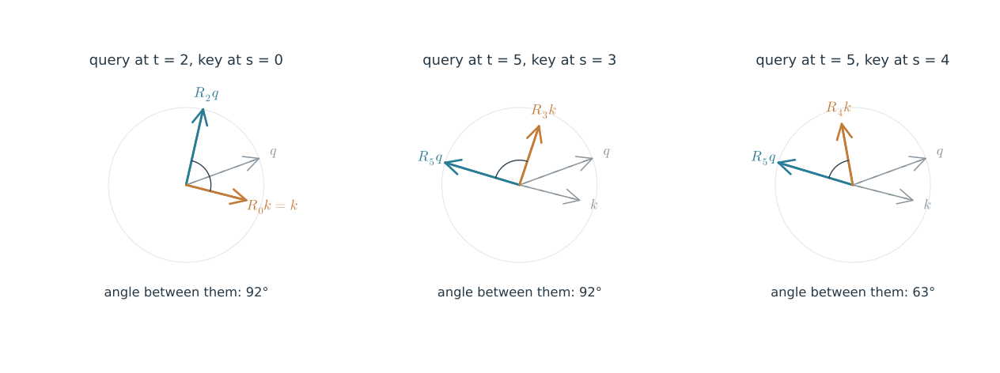

In [43]:
rope_rotation_diagram(0.5)

*Figure 32. One pair of a query (teal) and a key (amber), turned by $t\theta$ and $s\theta$; dashed: before turning. $\theta=0.5$ radian per token for visibility.*

- **$(t,s)=(2,0)$ and $(5,3)$:** the query is $2\theta$ ahead in both; angle 92°, same score.
- **$(5,4)$:** $\theta$ ahead; angle 63°, a different score.

In [44]:
c,sn=rope_tables(64,300,10_000f0)          # cos and sin of t·θᵢ for positions t = 0,…,299
rot(v,t)=apply_rope(v,c[:,t+1],sn[:,t+1])   # turn every pair of v by the angles of position t
q,k=randn(MersenneTwister(1),Float32,64),randn(MersenneTwister(2),Float32,64)
for (t,s) in ((5,2),(105,102),(250,247),(5,4))
    @printf("query at position %3d, key at %3d (distance %d): score %.4f\n",t,s,t-s,dot(rot(q,t),rot(k,s)))
end

query at position   5, key at   2 (distance 3): score -1.6047


query at position 105, key at 102 (distance 3): score -1.6047
query at position 250, key at 247 (distance 3): score -1.6047
query at position   5, key at   4 (distance 1): score 0.6866


**Check, all 32 pairs, random $q$ and $k$:** score −1.6047 at $(t,s)=(5,2),(105,102),(250,247)$; 0.6866 at distance 1.

**Fast and slow pairs.** With $q_{[i]},k_{[i]}$ pair $i$ of the query and the key, and $\varphi_i$ their angle before turning:

$$
(R_tq)^\top(R_sk)=\sum_{i=1}^{32}\underbrace{\lVert q_{[i]}\rVert\,\lVert k_{[i]}\rVert}_{\text{learned}}\,\cos\big(\underbrace{\varphi_i}_{\text{learned}}+(t-s)\,\underbrace{\theta_i}_{\text{fixed}}\big),
\qquad
\frac{2\pi}{\theta_i}=\text{tokens per turn}\in[6.3,\ 47{,}000] .
$$

- **Fast pair, like a second hand** (pair 1, 57° per token): its term changes at every distance, so it tells 1, 2 or 3 tokens back apart.
- **Slow pair, like an hour hand** (pair 32, 0.008° per token): its term is $\approx\cos\varphi_{32}$ at any distance in the window, so it compares content only.
- **A head chooses through $W_Q,W_K$:** to look at the previous token, it puts its weight in fast pairs with $\varphi_i=-\theta_i$, which all line up at $t-s=1$; to find the same name anywhere, in slow pairs.

| $t-s$ | pair 1 | pair 16 | pair 32 |
|---|---|---|---|
| 1 | 57° | 0.76° | 0.008° |
| 5 | 286° | 3.8° | 0.04° |
| 100 | 16 turns | 76° | 0.8° |

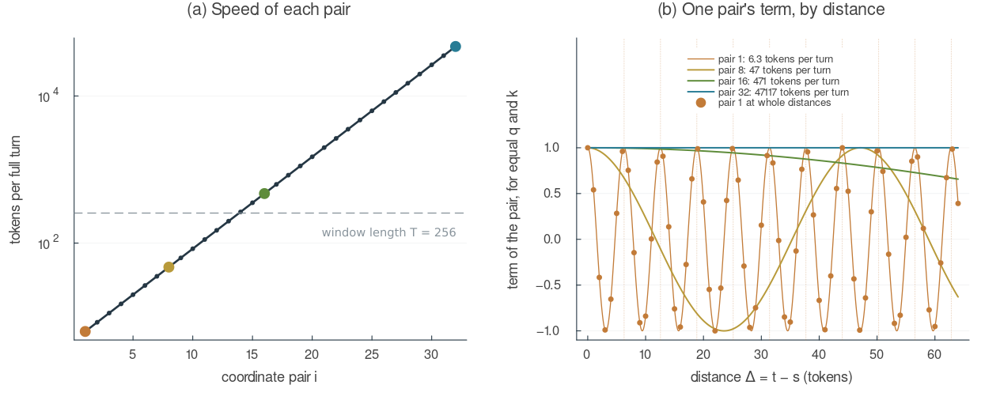

In [45]:
rope_plot(64,10_000)

*Figure 33. (a) Tokens per turn, $2\pi/\theta_i$, of the 32 pairs (log scale). (b) The term $\cos(\Delta\theta_i)$ of four pairs against the distance $\Delta=t-s$; dots: whole $\Delta$ for pair 1; dotted lines: multiples of $2\pi$.*

- **(a)** Each pair is 1.33 times slower than the previous one; pairs 1–13 turn at least once within 256 tokens.
- **(b)** Pair 1: 1, 0.54, −0.42 at $\Delta=0,1,2$, a period of 6.28 tokens. Pair 16: 0.66 at $\Delta=64$. Pair 32: 1 throughout.

### 6.6 Grouped-query attention

$H=6$ query heads in $H_{kv}=2$ groups of 3 (Ainslie et al., 2023); head $h$ uses the key and value of group $g=\lceil h/3\rceil$:

$$
\begin{aligned}
q^{(h)}_t&=W^{(h)}_Qx_t,\quad h=1,\ldots,6, &&\text{one query per head}\\
k^{(g)}_s&=W^{(g)}_Kx_s,\quad v^{(g)}_s=W^{(g)}_Vx_s,\quad g=1,2, &&\text{one key and value per group}\\
\alpha^{(h)}_{ts}&=\frac{\exp\big(q^{(h)\top}_tk^{(g)}_s/\sqrt{d_h}+M_{ts}\big)}{\sum_{s'=1}^{T}\exp\big(q^{(h)\top}_tk^{(g)}_{s'}/\sqrt{d_h}+M_{ts'}\big)},\quad
M_{ts}=\begin{cases}0,&s\le t\\-\infty,&s>t\end{cases} &&\text{causal softmax}\\
o^{(h)}_t&=\sum_{s=1}^{T}\alpha^{(h)}_{ts}\,v^{(g)}_s,\qquad \mathrm{Attn}_t=W_O\,[o^{(1)}_t;\ldots;o^{(6)}_t] &&\text{weighted average, heads mixed}
\end{aligned}
$$

- **Each head keeps its own $\alpha^{(h)}$:** different queries against the same keys.
- **Why share keys and values, not queries:** generating token $t$ needs only $q_t$, but $k_s,v_s$ for every $s\le t$ in every layer, stored and read again at each step (the **KV cache**):
$$\text{cached numbers per token}=2\cdot K\cdot H_{kv}\cdot d_h .$$
- **Two extremes:** $H_{kv}=H$ is multi-head attention; $H_{kv}=1$ is multi-query attention.

W_Q, W_O: 384 × 384 | W_K, W_V: 128 × 384 each (one key/value head per query head: 384 × 384)


2 key/value heads  KV cache:  1536 numbers per token (all 6 layers); a 256-token window: 1.6 MB in Float32
6 key/value heads  KV cache:  4608 numbers per token (all 6 layers); a 256-token window: 4.7 MB in Float32


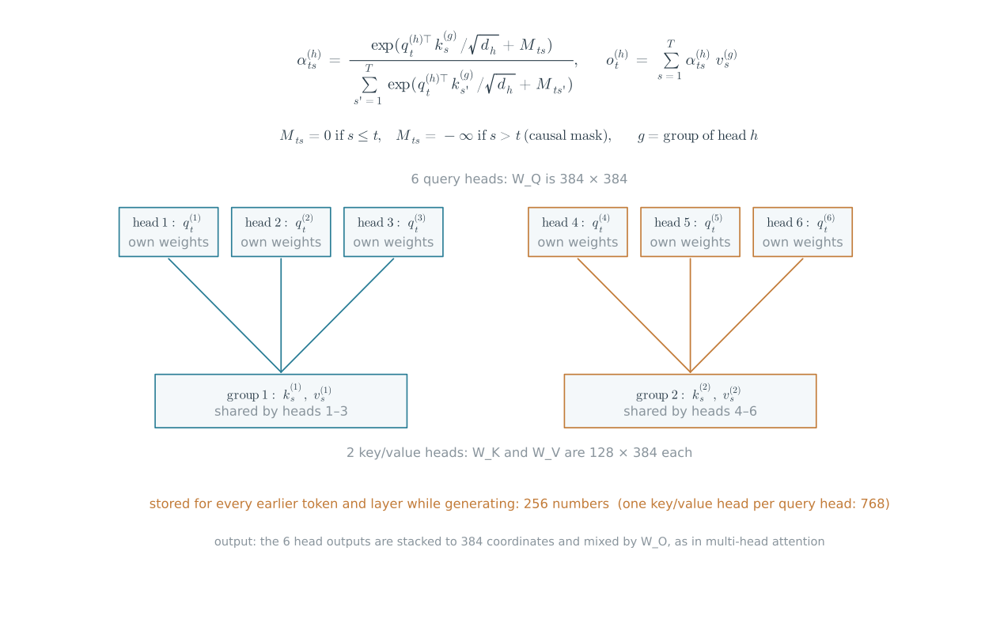

In [46]:
dh=lm_cfg.d÷lm_cfg.heads
@printf("W_Q, W_O: %d × %d | W_K, W_V: %d × %d each (one key/value head per query head: %d × %d)\n",
    lm_cfg.heads*dh,lm_cfg.d,lm_cfg.kv_heads*dh,lm_cfg.d,lm_cfg.heads*dh,lm_cfg.d)
for (name,Hk) in (("2 key/value heads",lm_cfg.kv_heads),("6 key/value heads",lm_cfg.heads))
    n=2*Hk*dh*lm_cfg.layers
    @printf("%-18s KV cache: %5d numbers per token (all %d layers); a 256-token window: %.1f MB in Float32\n",name,n,lm_cfg.layers,n*256*4/1e6)
end
gqa_diagram(lm_cfg.heads,lm_cfg.kv_heads;dh,d=lm_cfg.d)

*Figure 34. Six query heads (top) in two groups; the heads of a group (same colour) share the keys and values below.*

- **Cache:** $2\cdot6\cdot2\cdot64=1{,}536$ numbers per token, against $4{,}608$ with $H_{kv}=6$.
- **Parameters:** $W_K,W_V\in\mathbb R^{128\times384}$ instead of $384\times384$, 196,608 fewer values per layer.

### 6.7 RMSNorm, before each block

$$
\underbrace{\mathrm{RMSNorm}(x)=g\odot\frac{x}{\sqrt{\tfrac1d\sum_{i=1}^{d}x_i^2+\varepsilon}}}_{\text{this model}}
\qquad\qquad
\underbrace{\mathrm{LN}(x)=\gamma\odot\frac{x-\mu}{\sqrt{\sigma^2+\varepsilon}}+\beta}_{\text{Transformer classifier, BERT}}
$$

- **RMSNorm only rescales:** no mean, no shift; cheaper, and trains as well (Zhang and Sennrich, 2019). $g\in\mathbb R^{384}$ is learned; $2K+1=13$ of them.
- **Pre-norm:** only the copy entering a block is normalized. Over the $2K=12$ blocks $f_b$ (attention or feedforward):
$$
x^{(b)}=x^{(b-1)}+f_b\big(\mathrm{RMSNorm}(x^{(b-1)})\big)
\ \Longrightarrow\
x^{(2K)}=\underbrace{x^{(0)}}_{\text{token vector}}+\sum_{b=1}^{2K}\underbrace{f_b(\cdots)}_{\text{added by block }b},
\qquad
\frac{\partial x^{(2K)}}{\partial x^{(0)}}=\prod_{b}\Big(I+\frac{\partial f_b}{\partial x}\Big)=I+\cdots
$$
  The gradient reaches the first layer through $I$, however deep the model; in post-norm it crosses a normalization in every layer.
- **A last RMSNorm before the head:** the residual stream grows as blocks add to it.

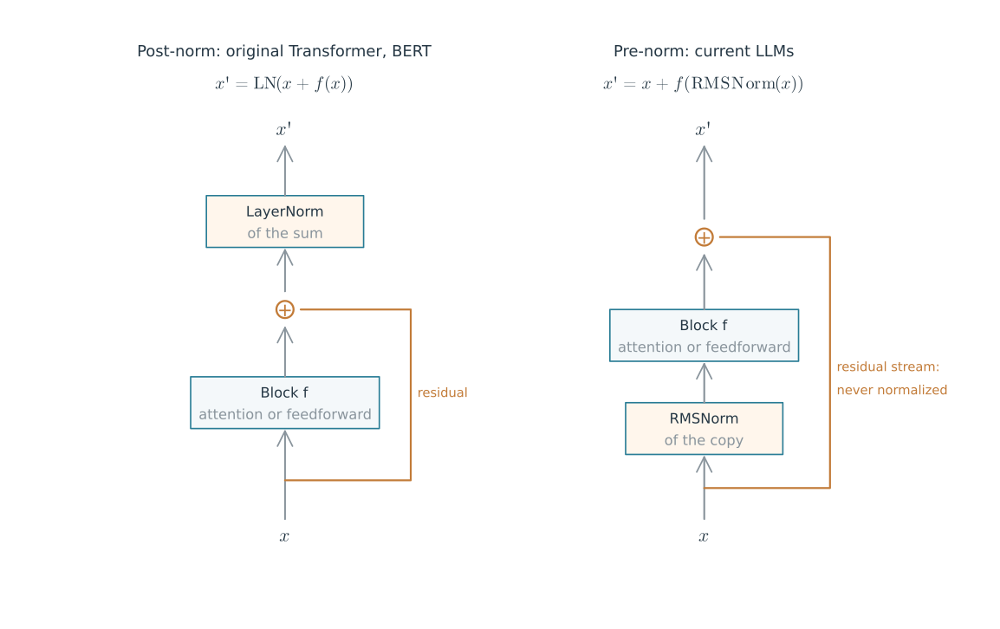

In [47]:
prenorm_diagram()

*Figure 35. Post-norm (left: the Transformer classifier, BERT) and pre-norm (right: this model); amber: the residual path. Left, it crosses a LayerNorm in every layer; right, it is a plain sum.*

### 6.8 SwiGLU feedforward

$$
\mathrm{FFN}(h)=W_2\big(\underbrace{\mathrm{SiLU}(W_1h)}_{1{,}024\text{ features}}\odot\underbrace{W_3h}_{1{,}024\text{ gates}}\big),\qquad
\mathrm{SiLU}(u)=u\,\sigma(u)=\frac{u}{1+e^{-u}},\qquad
W_1,W_3\in\mathbb R^{1024\times384},\ W_2\in\mathbb R^{384\times1024}.
$$

- **Feature $j$ is a product,** $\mathrm{SiLU}(w_{1j}^\top h)\cdot(w_{3j}^\top h)$: the linear gate scales it up, down or flips it, so one feature responds to two directions of $h$ together.
- **SiLU** is a smooth ReLU: $\approx u$ for large $u$, $\approx0$ for very negative $u$, slope never exactly 0.
- **Same size as a ReLU network of width $4d$:** $3\cdot d\cdot\tfrac83d=2\cdot d\cdot4d=8d^2$, hence the width $\tfrac83\cdot384=1{,}024$ (Shazeer, 2020).
- **Per position:** tokens interact only in attention.

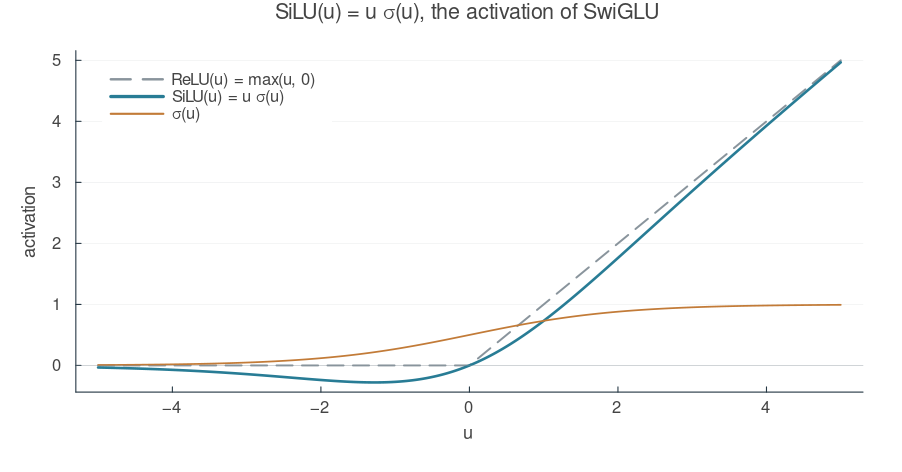

In [48]:
swiglu_plot()

*Figure 36. SiLU (teal), ReLU (grey, dashed) and $\sigma(u)$ (amber). SiLU and ReLU agree for large $|u|$; SiLU is smooth at 0 and dips to −0.28 at $u\approx-1.3$.*

### 6.9 Output head: the token table, used twice

$$
z_t=E^\top\,\mathrm{RMSNorm}\big(x^{(K)}_t\big)\in\mathbb R^{4096},\qquad
P(x_{t+1}=j\mid x_1,\ldots,x_t)=\frac{\exp(z_{tj})}{\sum_{j'=1}^{4096}\exp(z_{tj'})},\qquad
\mathcal L=-\frac1T\sum_{t=1}^{T}\log P(x_{t+1}\mid x_1,\ldots,x_t).
$$

- **Score of token $j$:** the inner product of the final vector with $E[:,j]$, the vector token $j$ enters with.
- **Tied:** no separate $4{,}096\times384$ output matrix; each column of $E$ is trained as input and as output.
- **Uniform guess:** $\mathcal L=\log4{,}096=8.32$.

In [49]:
nE=length(lm_initial.E)
@printf("E: %d × %d = %d values, %.0f%% of the %d parameters; an untied output matrix would add %d more\n",
    size(lm_initial.E)...,nE,100nE/n_params(lm_initial),n_params(lm_initial),nE)

E: 384 × 4096 = 1572864 values, 14% of the 11015040 parameters; an untied output matrix would add 1572864 more


### 6.10 Pretraining

- **Data:** each update uses $B=32$ windows of $T+1=257$ tokens at random places; $11{,}000\times32\times256\approx90$ million tokens (16% of the stream), no window used twice.
- **Optimizer:** Adam, $\beta=(0.9,0.95)$, gradients clipped to norm 1.
- **Learning rate** at update $q$, with $Q=11{,}000$ updates, $W=300$ warm-up updates, $\eta_{\max}=10^{-3}$, $\eta_{\min}=10^{-4}$:
$$
\eta_q=\begin{cases}
\eta_{\max}\,\dfrac{q}{W}, & q\le W,\\[3mm]
\eta_{\min}+\tfrac12(\eta_{\max}-\eta_{\min})\Big(1+\cos\Big(\pi\,\dfrac{q-W}{Q-W}\Big)\Big), & q>W.
\end{cases}
$$
  Warm-up: small steps while the weights are random and Adam's averages rest on few gradients. Cosine: from $\eta_{\max}$ ($\cos0=1$) to $\eta_{\min}$ ($\cos\pi=-1$), so the noisy updates settle.
- **Checks:** validation loss on 640 fixed windows; copies of the model after 25, 100, 300, 1,000, 3,000 and 11,000 updates.

`TRAIN_LM=true` refits on a GPU (about one hour); otherwise the saved fit is loaded.

11000 updates, 90 million tokens, 56 minutes | validation loss 1.465, perplexity 4.33


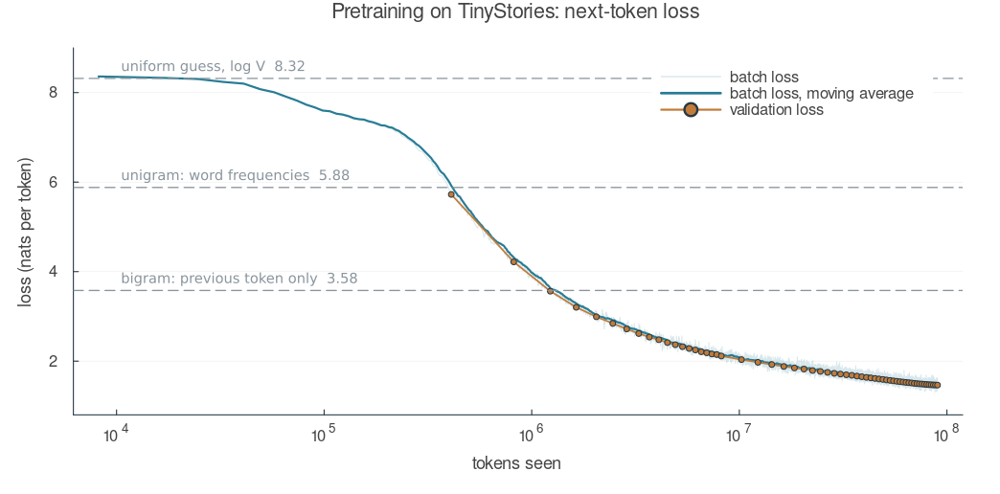

In [50]:
TRAIN_LM=false
ENV["JULIA_CUDA_HARD_MEMORY_LIMIT"]="10GiB"   # keep GPU memory within the card when refitting
lm_run=experiment_or_load("tinystories_lm",()->pretrain_tinystories(lm_data,lm_initial,lm_cfg;device=gpu_or_cpu()),
    RESULTS;rerun=TRAIN_LM)
lm_an=experiment_or_load("tinystories_lm_analysis",()->pretrain_analysis(lm_run,lm_data),RESULTS;rerun=TRAIN_LM)
@printf("%d updates, %.0f million tokens, %.0f minutes | validation loss %.3f, perplexity %.2f\n",lm_run.log.step[end],
    lm_run.log.tokens[end]/1e6,lm_run.seconds/60,lm_run.checks[end].val_loss,exp(lm_run.checks[end].val_loss))
lm_training_plot(lm_run,lm_an.base)

*Figure 37. Next-token loss against the number of tokens seen (log scale): every batch (faint), its moving average (at update $q$, the mean of the last $\min(50,\max(1,q/10))$ batches, rounded), and the validation loss. Dashed: three reference models.*

**Reference models**, counted on 20 million training tokens ($N$ tokens, $N(b)$ occurrences of $b$, $N(a,b)$ of $a$ directly followed by $b$) and scored on the validation stream:

$$
\begin{aligned}
\text{uniform:}&\quad P(x_{t+1}=b)=\frac1V=\frac1{4{,}096} &&\text{no information}\\
\text{unigram:}&\quad P(x_{t+1}=b)=\hat p(b)=\frac{N(b)}{N} &&\text{how common }b\text{ is}\\
\text{bigram:}&\quad P(x_{t+1}=b\mid x_t=a)=\lambda\,\underbrace{\frac{N(a,b)}{N(a)}}_{\hat p(b\mid a)}+(1-\lambda)\,\hat p(b) &&\text{the previous token only}
\end{aligned}
$$

$$
\hat\lambda=\arg\min_{\lambda\in\{0.50,\,0.55,\,\ldots,\,0.95\}}\ -\frac1n\sum_{t}\log\big[\lambda\,\hat p(x_{t+1}\mid x_t)+(1-\lambda)\,\hat p(x_{t+1})\big]=0.95 ,
$$

since with $\lambda=1$ a pair absent from the counts has $\hat p(b\mid a)=0$ and loss $-\log0=\infty$.
Example: ` the` occurs a million times, followed by ` little` 80,000 times, so $\hat p(\text{little}\mid\text{the})=0.08$.

**Perplexity** is the exponential of the loss:

$$
\mathrm{PPL}=e^{\mathcal L}=\Big(\prod_{t=1}^{n}\frac1{P(x_{t+1}\mid\cdot)}\Big)^{1/n},\qquad
P\equiv\tfrac1k\ \Rightarrow\ \mathcal L=\log k,\ \ \mathrm{PPL}=k:
$$

the number of equally likely tokens the model is, on average, choosing among.

| | loss | perplexity |
|---|---|---|
| uniform | 8.32 | 4,096 |
| unigram | 5.88 | 358 |
| bigram | 3.58 | 36 |
| our model, final | 1.465 | 4.3 |

- **Below unigram** (after 0.4 million tokens): the model uses context. **Below bigram** (after 1.2 million, within the warm-up): it uses more than the previous token. The gap between bigram and model is the gain from the longer context.
- **Validation equals training loss:** no window is seen twice, so no memorization; the curve still falls at the end.

### 6.11 What the model writes during training

The saved copies continue `Once upon a time` with the same random numbers. With $z_t=E^\top\mathrm{RMSNorm}(x_t)$ the scores of the next token, temperature $\tau=0.8$ and $\mathcal K_t$ the 40 tokens with the largest scores:

$$
P(x_{t+1}=j)=\frac{\exp(z_{tj}/\tau)}{\sum_{j'\in\mathcal K_t}\exp(z_{tj'}/\tau)}\ \ \text{for } j\in\mathcal K_t,\qquad 0\ \text{otherwise},
$$

up to 120 tokens. $\tau<1$ sharpens the distribution; keeping 40 tokens removes the unlikely tail.

In [51]:
for (s,t,x) in zip(lm_an.steps,lm_an.tokens,lm_an.samples)
    @printf("---- after %d updates (%.1f million tokens)\n",s,t/1e6)
    println(replace(x,"<|endoftext|>"=>" [end of story]"),"\n")
end

---- after 0 updates (0.0 million tokens)
Once upon a time grace wheat wheat wheat harmless flo cast holes creat Youardenarden She“ She“lc sharing apple celebrse staff dessert splashed sharing mummy cast salad crane Come Come apple apple noticed happen happen wheat picturesse lamp everything drop Mommy noticed wheatromrom feathers feathers noticedD different dessert dessert Timmy Timmy rolling dead stream drop Jack'd'd noticed cranerom cast= stream crane apple cherries pr excitementumpy skytime d saysistedisted lift everything everything everything Mommy cauliflowerext perD noticed slept never sky sky sky wheat goodbyesese sl cast cast minutes noticed apple apple rolling stepse bought fan never though buck though sk Jack grass cast

---- after 25 updates (0.2 million tokens)
Once upon a time and said to to big.. It....,.,.. the. the. His oven.. nurse. and wasD the... a. and.. to. the.. and.. and and.,.'m oven.. smiled.... telephone bikes. up..! to had. Max, ord.. were,. said "..... at 

- **0:** random tokens. **25:** frequent tokens (`the`, `.`, `and`) in no order. **100:** phrases (`there was a`, `One day`) without sense.
- **300:** a short grammatical story ending with `<|endoftext|>`. **1,000 and 3,000:** paragraphs with one named character.
- **11,000:** a problem and its solution, with the girl, her ball and the bird consistent across sentences; a few errors remain.

### 6.12 How much does the context help?

Loss at position $t$, averaged over $W=256$ validation windows that start at random places:

$$
L(t)=\frac1W\sum_{w=1}^{W}-\log P\big(x^{(w)}_{t+1}\mid x^{(w)}_1,\ldots,x^{(w)}_t\big),\qquad t=1,\ldots,256,
$$

the loss with $t$ tokens of context.

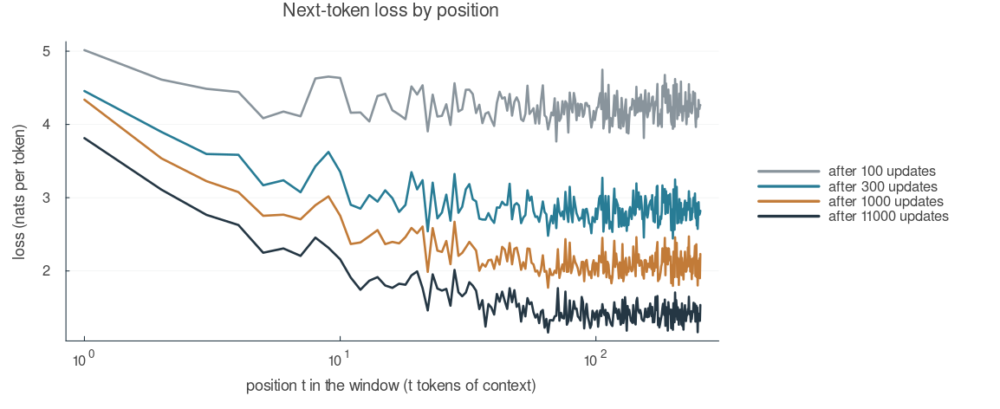

In [52]:
position_loss_plot(lm_an.pos[[3,4,5,7]];labels=["after $(s) updates" for s in lm_an.steps[[3,4,5,7]]])

In [53]:
@printf("Final model, 64 validation windows: %.0f%% of the tokens already appeared earlier in the window\n",100lm_an.seen.share_seen)
@printf("  loss on these tokens %.2f | on tokens new to the window %.2f\n",lm_an.seen.loss_seen,lm_an.seen.loss_new)

Final model, 64 validation windows: 52% of the tokens already appeared earlier in the window
  loss on these tokens 0.93 | on tokens new to the window 2.19


*Figure 38. $L(t)$ for four saved copies of the model (log scale for $t$).*

- **Final model:** $L(1)=3.8$, close to the bigram (3.58); $L(t)$ falls until $t\approx50$, then stays near 1.4.
- **Gain from context, $L(1)-L(256)$:** 0.8 after 100 updates, 2.4 at the end.
- **Repeated tokens,** $x_{t+1}\in\{x_1,\ldots,x_t\}$: 52% of all tokens, with loss 0.93 against 2.19 for tokens new to the window.

### 6.13 An emergent ability: copying from the context

Copying a word from earlier in the text is an ability that appears suddenly during training, while the loss falls smoothly.

**Test.** 20 invented names that never occur in the stories. The tokenizer splits each into $m=4$ to 7 pieces $n_1,\ldots,n_m$, for example (· marks the leading space)

` Zorbik` → `·Z` | `or` | `b` | `ik`, so $m=4$ and $n_1=$ `·Z`, $n_2=$ `or`, $n_3=$ `b`, $n_4=$ `ik`.

Each name is mentioned three times in the same story; for Zorbik the mentions start at token positions 12, 17 and 31:

> Once upon a time, there was a little boy named **Zorbik**. **Zorbik** loved to play in the park. One day, **Zorbik**

**Probability of the pieces.** At mention $r$, the probability of piece $j$ given all text before it, for the first piece and for the later pieces:

$$
p_r(j)=P\big(n_j\mid\text{text before }n_j\text{ at mention }r\big),\qquad
\underbrace{p_r(1)}_{\text{first piece}},\qquad
\underbrace{\tfrac1{m-1}\textstyle\sum_{j=2}^{m}p_r(j)}_{\text{later pieces}},\qquad r\in\{1,3\}.
$$

At $r=1$ there is nothing to copy; at $r=3$ only copying predicts the later pieces.

**Attention to the piece that came next.** Reading $n_j$ at mention 3 (query position $t$), the token to predict is $n_{j+1}$, which followed $n_j$ at mention 1 (key position $s$). For layer $\ell$ and head $h$, the attention weight on that one key, averaged over the pieces and the 20 names:

$$
S_{\ell h}=\frac{1}{\sum_{\text{names}}(m-1)}\sum_{\text{names}}\ \sum_{j=1}^{m-1}\alpha^{(\ell,h)}_{t_j s_j},\qquad
t_j=\text{position of }n_j\text{ at mention 3},\quad s_j=\text{position of }n_{j+1}\text{ at mention 1}.
$$

For Zorbik, $(t_j,s_j)=(31,13),(32,14),(33,15)$: ·Z → or, or → b, b → ik.
Since $\sum_{s\le t}\alpha_{ts}=1$, $S_{\ell h}\in[0,1]$ is the share of the head's attention on the token to copy; spread evenly over the 30 to 40 earlier tokens it would be about 0.03.

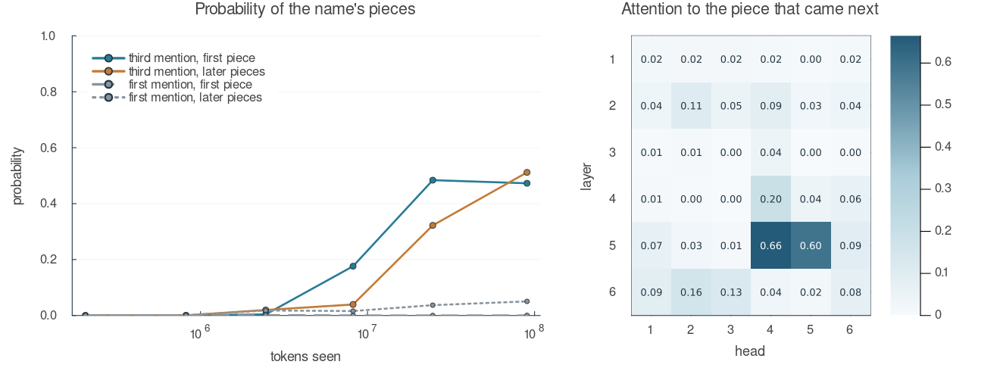

In [54]:
name_copy_plot(lm_an)

*Figure 39. Left: first and later pieces at mentions 1 and 3, averaged over the 20 names, for every saved copy. Right: $S_{\ell h}$ for each layer and head of the final model.*

- **Mention 1:** near 0. **Mention 3, later pieces:** below 0.04 up to 1,000 updates (8 million tokens), 0.32 at 3,000, 0.51 at the end.
- **Emergence:** between updates 1,000 and 3,000 copying jumps from 0.04 to 0.32, while the validation loss (Figure 37) falls smoothly from 2.12 to 1.77. Copying helps only a small share of the tokens, so the average loss does not show it.
- **Heads 4 and 5 of layer 5:** $S=0.66$ and $0.60$, about 20 times the even share; all other heads 0.20 or less. These heads attend to the piece that followed the current one before, an **induction head**:
$$
x_t=A,\quad x_{s-1}=A,\quad x_s=B\quad(s<t)
\qquad\Longrightarrow\qquad
\alpha_{ts}\ \text{large},\quad o_t\approx v_s,\quad P(x_{t+1}=B)\uparrow .
$$

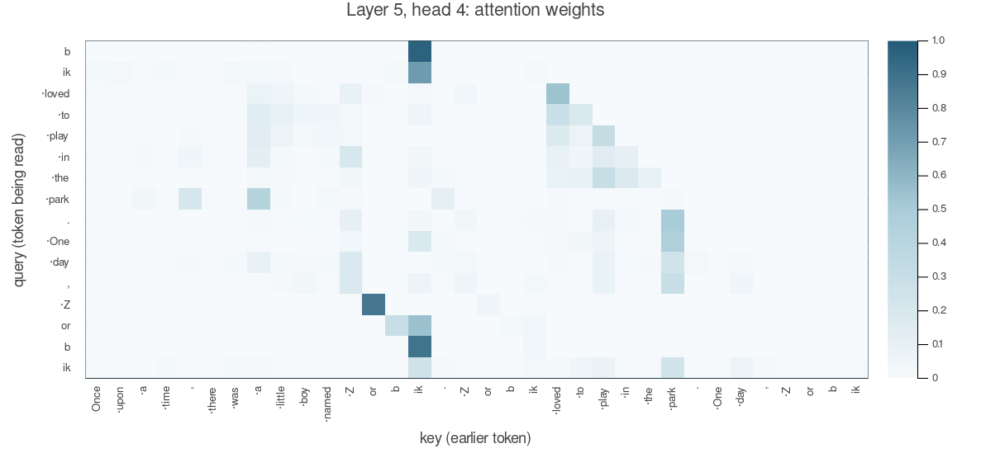

In [55]:
head_attention_plot(lm_run.model,lm_cfg,lm_tok,name_story("Zorbik"),5,4;from=19)

*Figure 40. Weights $\alpha_{ts}$ of layer 5, head 4, on the Zorbik story: rows $t$ from the second mention on, columns $s$ earlier; "·" marks a leading space.*

- **Mention 3:** reading `b`, weight on `ik`, which followed `b` before; reading `or`, on `b` and `ik`.
- **Reading `·Z`:** weight on the first `·Z`. **Other tokens:** weight spread over recent words.

## 7. Post-training: from a text model to an assistant

A pretrained model continues text; an assistant answers a request and stops.
**Supervised fine-tuning** (SFT), the first step of post-training, trains a pretrained model with the next-token loss on conversations, scored on the answers only.
(Training on preferences between answers, the usual next step, is not done here.)

Model: SmolLM2-135M (Allal et al., 2025).

### 7.1 The pretrained model: SmolLM2-135M

The decoder of Figure 30, with the settings of its `config.json`:

- **Sizes:** $V=49{,}152$ (digits split singly), $d=576$, $K=30$ layers, $H=9$ query heads of $d_h=64$ in $H_{kv}=3$ groups, SwiGLU width $1{,}536=\tfrac83\cdot576$, tied $E$ (28.3 million values, 21% of all).
- **KV cache:** $2\cdot30\cdot3\cdot64=11{,}520$ numbers per token; 189 MB in bfloat16 for its longest context, 8,192 tokens.
- **RoPE base 100,000:** $\theta_i=100{,}000^{-2(i-1)/64}$; the slowest pair turns once in 440,000 tokens, so positions stay distinct over 8,192 tokens.
- **Pretraining:** about 2 trillion tokens of web text, code and mathematics.

The weights are read from `model.safetensors` (bfloat16, converted to Float32) into the layout of `gpt_model`.

In [56]:
smol_tok=hf_tokenizer(joinpath(SMOL_DIR_DEFAULT,"tokenizer.json"))
smol,smol_cfg=smol_model()
@printf("SmolLM2-135M: %d parameters, %d layers, width %d, vocabulary %d\n",n_params(smol),smol_cfg.layers,smol_cfg.d,smol_cfg.V)
ids=bpe_encode("The capital of France is",smol_tok); P=next_token_probs(smol,ids,smol_cfg)[:,end]
println("Next token after \"The capital of France is\": ",
    join([@sprintf("%s %.2f",repr(bpe_decode([i],smol_tok)),P[i]) for i in partialsortperm(P,1:5;rev=true)],", "))
out=generate(smol,bpe_encode("Gravity is the force that",smol_tok),smol_cfg;n=25,temperature=0)
println("Greedy continuation: ",bpe_decode(out,smol_tok))

SmolLM2-135M: 134515008 parameters, 30 layers, width 576, vocabulary 49152


Next token after "The capital of France is": " the" 0.26, " Paris" 0.09, " located" 0.07, " called" 0.04, " a" 0.04
Greedy continuation: 

Gravity is the force that holds the Earth and the Moon together.

The Moon is a satellite of the Earth. It is a rocky body that


- **Facts:** ` Paris` is among the likely next tokens, after ` the`.
- **Fluent text:** the greedy continuation (the most likely token at each step) is a correct sentence.
- **No notion of an answer:** it continues text; nothing marks where an answer ends.

### 7.2 Conversations as text, and the loss on answers

A conversation is one text, with special tokens of the vocabulary:

```
<|im_start|>user
{instruction}<|im_end|>
<|im_start|>assistant
{answer}<|im_end|>
```

$$
\mathcal L_{\text{SFT}}(\theta)=-\frac{\sum_{t} w_t\,\log P_\theta(x_{t+1}\mid x_1,\ldots,x_t)}{\sum_t w_t},\qquad
w_t=\begin{cases}1,& x_{t+1}\ \text{in the answer, including its final end token},\\ 0,& \text{otherwise.}\end{cases}
$$

- **Prompt not scored:** the model learns to answer, not to write instructions.
- **Final `<|im_end|>` scored:** the model learns to stop.

**Data:** Alpaca, cleaned (Taori et al., 2023): 51,760 instructions with answers written by an OpenAI model. Shuffled; 256 for validation, the next 15,000 for training.

In [57]:
alpaca=shuffle(MersenneTwister(11),read_alpaca())
ex=chat_tokens(alpaca[300],smol_tok)
pcs=[replace(bpe_decode([i],smol_tok),"\n"=>"\\n") for i in ex.ids]
println(join([ex.w[t]==1 ? "[$(pcs[t])]" : pcs[t] for t in eachindex(pcs)],""))
@printf("\n%d tokens, %d scored (in brackets)\n",length(ex.ids),Int(sum(ex.w)))

<|im_start|>user\nWrite the lyrics to the chorus of a song about resilience.<|im_end|>\n<|im_start|>assistant\n[(][C][hor][us][)][\n][When][ the][ road][ gets][ rough][,][ and][ the][ storm][ rolls][ in][\n][Just][ breathe][ and][ dig][ deep][,][ let][ resilience][ begin][\n][R][ise][ through][ the][ trials][,][ all][ the][ struggles][ you][ face][ ][\n][With][ a][ heart][ full][ of][ hope][,][ and][ an][ unwavering][ grace][\n][\n][You][ are][ stronger][ than][ you][ know][,][ don]['t][ let][ it][ get][ you][ down][\n][Per][se][vere][ through][ the][ highs][,][ and][ the][ lows][ will][ come][ around][\n][So][ hold][ onto][ your][ faith][,][ and][ keep][ pushing][ through][\n][For][ every][ challenge][ you][ conquer][,][ brings][ a][ stronger][ you][.][<|im_end|>]

127 tokens, 106 scored (in brackets)


One training conversation, token by token; the tokens in brackets have $w_t=1$ (106 of 127): the answer and its final `<|im_end|>`.

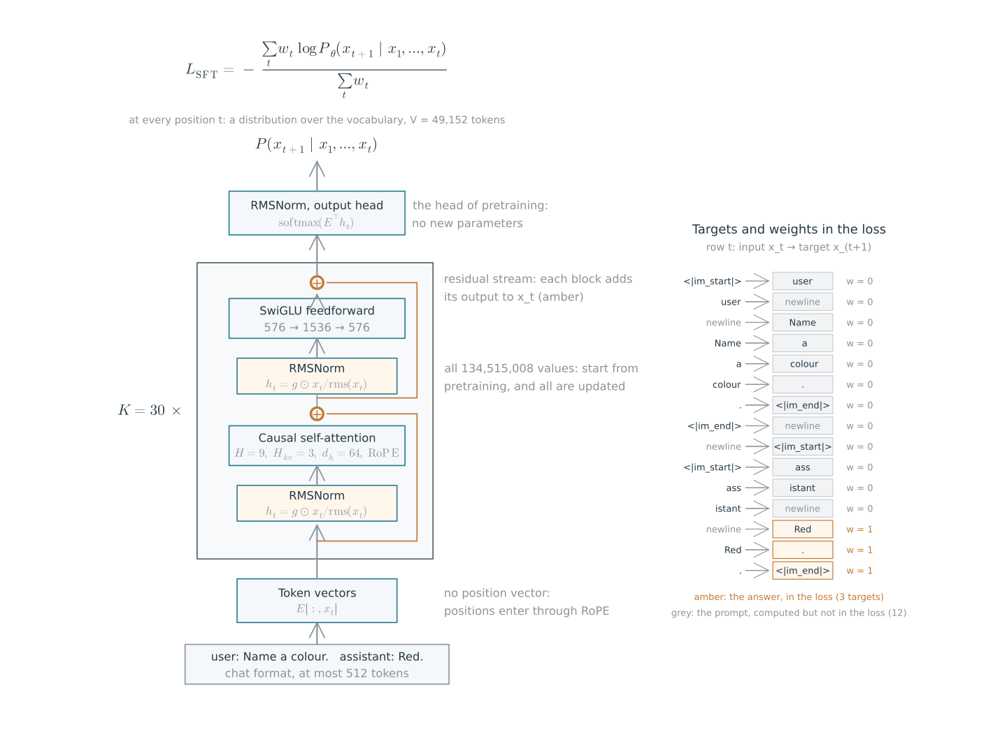

In [58]:
demo=chat_tokens((; prompt="Name a colour.", answer="Red."),smol_tok)
sft_diagram(smol_cfg,[bpe_decode([i],smol_tok) for i in demo.ids],demo.w;
    title="user: Name a colour.   assistant: Red.",n_params=n_params(smol))

*Figure 41. Fine-tuning on one short conversation. Left: SmolLM2 reading the conversation (bottom) and giving a next-token distribution at every position (top). Right: at each position $t$, the token read, the target $x_{t+1}$ and its weight $w_t$.*

- **Model:** the pretrained decoder and output head; all 134.5 million values are trained further.
- **Input:** the whole conversation; through the causal mask, the prediction of `Red` uses the instruction.
- **Loss:** 3 of the 15 predictions (`Red`, `.`, `<|im_end|>`, with $w_t=1$).

**Settings.**

- **Batches:** 4 conversations, padded with `<|endoftext|>` ($w_t=0$) to the longest, at most 512 tokens; one pass over the 15,000 conversations, 3,750 updates.
- **Optimizer:** Adam, $\beta=(0.9,0.95)$, gradients clipped to norm 1; the learning-rate schedule of pretraining with $W=100$, $\eta_{\max}=5\times10^{-5}$, $\eta_{\min}=5\times10^{-6}$, 20 times smaller, so the model changes only a little.
- **Memory:** each layer is recomputed in the backward pass instead of stored (gradient checkpointing).

`TRAIN_SFT=true` refits on a GPU (about 45 minutes); otherwise the saved fit is loaded.

15000 conversations, 3750 updates, 46 minutes | validation answer loss 1.902 before, 1.495 after


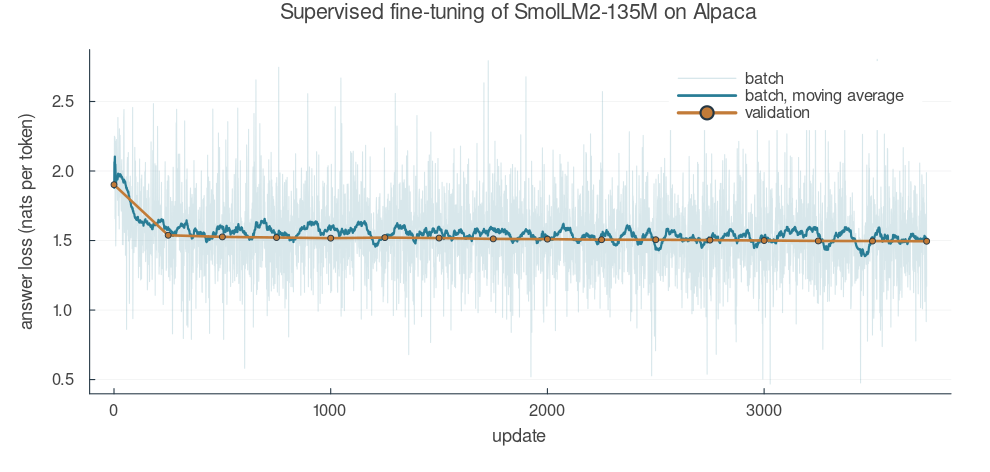

In [59]:
TRAIN_SFT=false
sft=experiment_or_load("smollm2_sft",()->sft_experiment(smol_tok,smol,smol_cfg;device=gpu_or_cpu()),RESULTS;rerun=TRAIN_SFT)
@printf("%d conversations, %d updates, %.0f minutes | validation answer loss %.3f before, %.3f after\n",sft.n_train,
    sft.run.log.step[end],sft.run.seconds/60,sft.run.checks[1].val_loss,sft.run.checks[end].val_loss)
sft_training_plot(sft.run)

*Figure 42. $\mathcal L_{\text{SFT}}$ during fine-tuning: every batch of 4 conversations (faint), its moving average over the last 50 batches, and $\mathcal L_{\text{SFT}}$ on the 256 validation conversations every 250 updates.*

- **1.90 → 1.54 in the first 250 updates** (1,000 conversations), then 1.50 after 15,000: the format (where the answer starts, its style, when to stop) is learned first.
- **Batch losses from 0.5 to 2.5:** 4 conversations of different difficulty per batch.

### 7.3 Answers before and after

Six requests not in the training data, in the conversation format, answered by the model before and after fine-tuning.
**Greedy decoding:** at each step the next token is the one with the largest score,

$$
x_{t+1}=\arg\max_j\ z_{tj},\qquad z_t=E^\top\mathrm{RMSNorm}(x_t).
$$

- **Why greedy:** the output depends only on the model, so before and after are compared without the luck of a random draw.
- **Stopping:** `<|im_end|>` is a single token of the vocabulary; generation stops when it is chosen, or after 120 tokens.

In [60]:
short(s;n=260)=length(s)<=n ? s : first(s,n)*" …"
for a in sft.answers
    println("==== ",a.prompt)
    println("before: ",short(replace(a.before.text,"\n"=>" / ")),a.before.stopped ? "" : "  [no <|im_end|> within 120 tokens]")
    println("after:  ",short(replace(a.after.text,"\n"=>" / ")),a.after.stopped ? "" : "  [no <|im_end|> within 120 tokens]")
end

==== What is the capital of France?
before: What is the capital of France? / What is the capital of France? / What is the capital of France? / What is the capital of France? / What is the capital of France? / What is the capital of France? / What is the capital of France? / What is the capital of France …  [no <|im_end|> within 120 tokens]
after:  The capital of France is Paris.<|im_end|>
==== Give three tips for staying healthy.
before: Give three tips for staying healthy. / Assistant / Assistant / Assistant / Assistant / Assistant / Assistant / Assistant / Assistant / Assistant / Assistant / Assistant / Assistant / Assistant / Assistant / Assistant / Assistant / Assistant / Assistant / Assis …  [no <|im_end|> within 120 tokens]
after:  1. Eat a balanced diet: Eating a healthy diet rich in fruits, vegetables, whole grains, lean proteins, and healthy fats can help you maintain a healthy weight, reduce your risk of chronic diseases, and improve your overall health. /  / 2. Stay active: 

- **Before:** the conversation is text to continue: the question repeated, "Assistant" again and again, French turned into Spanish; never `<|im_end|>`. Once a phrase repeats, copying from the context makes the next repetition more likely, and greedy decoding always takes it: the text loops.
- **After:** an answer in the expected form for every request; 4 of 6 end with `<|im_end|>`, two longer ones are cut at 120 tokens.
- **Abilities unchanged:** the translation is wrong and the haiku is not 5-7-5; 15,000 examples do not add what pretraining did not learn.

### 7.4 What changed, and what did not

**Facts.** 20 facts as text to complete (e.g. "The capital of France is" → " Paris"). With the answer split into tokens $a_1,\ldots,a_n$ after the prompt $c$:

$$
\log P(\text{answer}\mid\text{prompt})=\sum_{i=1}^{n}\log P\big(a_i\mid c,a_1,\ldots,a_{i-1}\big),\qquad
\text{top}\iff a_i=\arg\max_j P\big(j\mid c,a_1,\ldots,a_{i-1}\big)\ \text{for every } i,
$$

before → after fine-tuning. "top" means greedy decoding writes the answer.

In [61]:
for f in sft.facts
    @printf("%-58s %7.2f → %6.2f   %s → %s\n",f.prompt*" |"*f.answer,f.before.logp,f.after.logp,
        f.before.top1 ? "top" : "  -",f.after.top1 ? "top" : "  -")
end
@printf("\nMost likely completion: %d of 20 before, %d of 20 after | mean log-probability %.2f before, %.2f after\n",
    count(f->f.before.top1,sft.facts),count(f->f.after.top1,sft.facts),
    mean(f.before.logp for f in sft.facts),mean(f.after.logp for f in sft.facts))

The capital of France is | Paris                             -2.37 →  -0.52     - → top
The capital of Japan is | Tokyo                              -1.70 →  -0.13   top → top
The capital of Italy is | Rome                               -2.39 →  -0.53     - → top
The largest planet in the solar system is | Jupiter          -0.64 →  -0.32   top → top
Water is made of hydrogen and | oxygen                       -0.20 →  -0.06   top → top
Romeo and Juliet was written by William | Shakespeare        -0.01 →  -0.01   top → top
The first president of the United States was George | Washington   -0.02 →  -0.02   top → top
The chemical symbol for gold is | Au                         -0.22 →  -0.16   top → top
The Earth revolves around the | Sun                          -0.25 →  -0.33   top → top
A triangle has three | sides                                 -1.22 →  -0.86   top → top
The opposite of hot is | cold                                -0.16 →  -0.19   top → top
The boiling point of water

- **Top completion: 15 → 17 of 20** ("Paris", "Rome", "plants" gained; "relativity" lost); mean log-probability −1.10 → −0.73.
- **Why:** the training answers are short factual sentences, so a sentence now ends with the fact more often. What the model knows comes from pretraining.

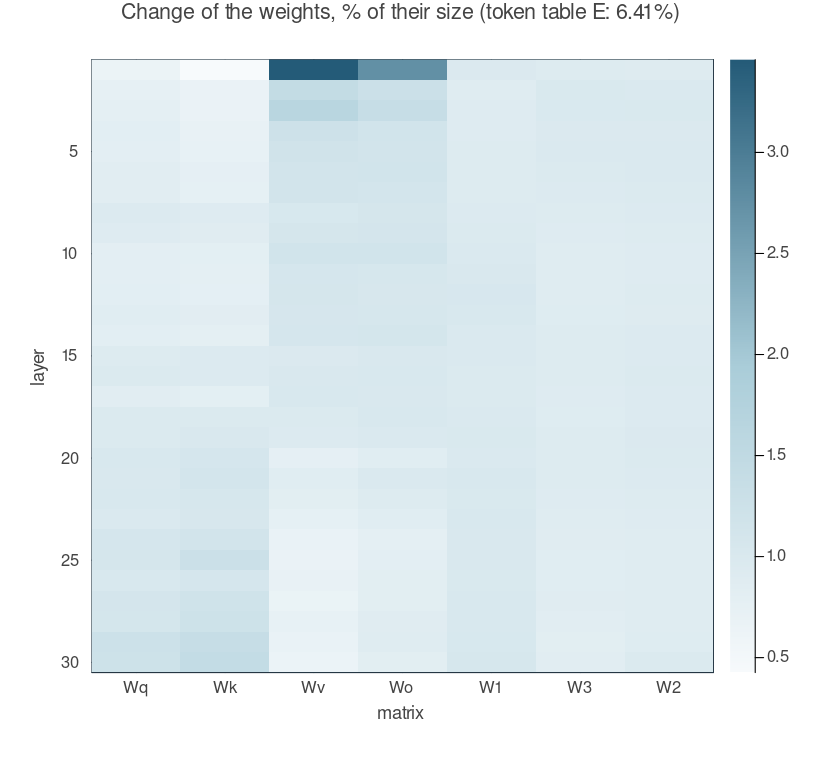

In [62]:
weight_change_plot(sft.change)

*Figure 43. Relative change $\lVert W_{\text{after}}-W_{\text{before}}\rVert/\lVert W_{\text{before}}\rVert$ of every weight matrix, in percent (rows: layers; columns: the attention matrices $W_Q,W_K,W_V,W_O$ and the feedforward matrices $W_1,W_3,W_2$; the title gives $E$).*

- **About 1% per matrix;** largest in layer 1's $W_V$ (3.5%) and $W_O$ (2.8%).
- **$E$: 6.4%,** spread over all rows: as the output head, every update lowers the scores of all tokens that were not the target.

In [63]:
ΔE=vec(sqrt.(sum(abs2,sft.run.model.E.-smol.E;dims=1)))./vec(sqrt.(sum(abs2,smol.E;dims=1)))
top=partialsortperm(ΔE,1:10;rev=true)
println("Most changed rows of E: ",join([@sprintf("%s %.0f%%",repr(bpe_decode([i],smol_tok)),100ΔE[i]) for i in top],", "))
@printf("Median change of a row: %.1f%%\n",100median(ΔE))

Most changed rows of E: "Perhaps" 23%, "Several" 23%, "Considering" 22%, "Generally" 22%, " obviously" 21%, "Contrary" 21%, "Among" 20%, "Obviously" 20%, "Typically" 20%, "Interestingly" 20%
Median change of a row: 6.0%


- **Most changed rows of $E$,** $\ \lVert E_{\text{after}}[:,j]-E_{\text{before}}[:,j]\rVert/\lVert E_{\text{before}}[:,j]\rVert$ for token $j$ (about 20%, median 6%): sentence openers without a leading space (`Perhaps`, `Generally`, `Typically`), the first word of an answer after `assistant` and a line break.

**Summary.** 15,000 examples and weight changes of about 1% teach the form of an answer and when to stop; knowledge and abilities stay those of pretraining.